
# Misc plots for main Fig 1

In [18]:

import sys
sys.path.append("C:\scripts\Imaging analysis")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
# import decon
from scipy.stats import chisquare
import pandas as pd
from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity

import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from activitymode import Mode

from ephysSession import Session
import behavior
cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 


In [94]:
naive_paths = [
               [ r'J:\ephys_data\CW48\python\2024_10_29',
                # r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                r'J:\ephys_data\CW48\python\2024_11_01',
                r'J:\ephys_data\CW48\python\2024_11_02',
                r'J:\ephys_data\CW48\python\2024_11_03',
                r'J:\ephys_data\CW48\python\2024_11_04',
                r'J:\ephys_data\CW48\python\2024_11_05',
                r'J:\ephys_data\CW48\python\2024_11_06',],

                 [r'M:\data\CW99\python\2026_05_09',
                  r'M:\data\CW99\python\2026_05_08'],
                  
                ]

trained_paths_high_performance = [
            # [ r'K:\data\CW69\python\2025_12_19',
            #   ],
            [
              # r'L:\data\CW68\python\2025_12_10',
              # r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            [r'L:\data\CW70\python\2025_11_02',
              r'L:\data\CW70\python\2025_10_28',
             ],
            # [r'G:\ephys_data\CW65\python\2025_02_25',
            #   ],
            [
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [
              # r'K:\data\CW85\python\2026_02_07',
              # r'K:\data\CW85\python\2026_02_10',
              r'K:\data\CW85\python\2026_02_13',
             
              ],
            
            [
              # r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_14',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],

             [
              r'P:\data\CW92\python\2026_06_17',
              r'P:\data\CW92\python\2026_06_18',
              r'P:\data\CW92\python\2026_06_19',
              r'P:\data\CW92\python\2026_06_21',
              r'P:\data\CW92\python\2026_06_23',
              r'P:\data\CW92\python\2026_06_24',
              r'P:\data\CW92\python\2026_06_25',
              r'P:\data\CW92\python\2026_06_26',
              r'P:\data\CW92\python\2026_06_27',
              r'P:\data\CW92\python\2026_06_28',
              r'P:\data\CW92\python\2026_06_29',
              r'P:\data\CW92\python\2026_06_30',
              r'P:\data\CW92\python\2026_07_01',

             ]



            ]

trained_paths = [
            [ r'K:\data\CW69\python\2025_12_19',
              ],
            # [r'L:\data\CW68\python\2025_12_10',
            #   r'L:\data\CW68\python\2025_12_12',
            #   r'L:\data\CW68\python\2025_12_13',
            #   r'L:\data\CW68\python\2025_12_15',
            #   ],
            # [r'L:\data\CW70\python\2025_11_04',

            #  ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [r'H:\ephys_data\CW47\python\2024_10_17',
              r'H:\ephys_data\CW47\python\2024_10_22',
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
              r'K:\data\CW85\python\2026_02_13',
             
              ],
            
            [r'K:\data\CW84\python\2026_03_11',             

             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],

              [
              r'P:\data\CW92\python\2026_06_17',
              r'P:\data\CW92\python\2026_06_18',
              r'P:\data\CW92\python\2026_06_19',
              r'P:\data\CW92\python\2026_06_21',
              r'P:\data\CW92\python\2026_06_23',
              r'P:\data\CW92\python\2026_06_24',
              r'P:\data\CW92\python\2026_06_25',
              r'P:\data\CW92\python\2026_06_26',
              r'P:\data\CW92\python\2026_06_27',
              r'P:\data\CW92\python\2026_06_29',
              r'P:\data\CW92\python\2026_07_01',

             ]

             
            ]

In [21]:
import numpy as np

def smooth_traces(trace_list, window=25):
    """
    Smooth each trace by averaging over a sliding window, then trim the first
    and last `window` entries (edge effects).

    Parameters
    ----------
    trace_list : list of array-like
        Each element is a 1D array of performance (e.g. all_correct_arr).
    window : int
        Number of trials over which to average; also number of points trimmed
        from each end (default 25).

    Returns
    -------
    list of np.ndarray
        Smoothed traces with first and last `window` entries removed. Length of
        each trace is len(original) - 2*window (or full length if too short).
    """
    if window < 2:
        return [np.asarray(arr).copy() for arr in trace_list]
    kernel = np.ones(window) / window
    out = []
    for arr in trace_list:
        arr = np.asarray(arr)
        smoothed = np.convolve(arr, kernel, mode='same')
        if len(arr) <= 2 * window:
            out.append(smoothed)
        else:
            out.append(smoothed[window:-window])
    return out

# Example: smoothed = smooth_traces(all_correct_arr, window=25)
# Then plot smoothed instead of all_correct_arr (x-axis: np.arange(len(smoothed[0])) or offset by window)

## Behavior

In [76]:
all_correct_arr = []
all_perf_by_mouse_naive = []
for paths in naive_paths:
    perf = []
    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
        earlylick, correctarr, numtrials = s1.get_acc_conv(window=50)
        all_correct_arr.append(correctarr)
        perf.append(np.mean(correctarr))
    all_perf_by_mouse_naive.append(perf)

all_correct_arr_sm = smooth_traces(all_correct_arr, window=25)

18 trials removed for stability reasons
only ppyr neurons: 333 --> 169
16 trials removed for stability reasons
only ppyr neurons: 299 --> 147
11 trials removed for stability reasons
only ppyr neurons: 225 --> 81
28 trials removed for stability reasons
only ppyr neurons: 270 --> 147
84 trials removed for stability reasons
only ppyr neurons: 268 --> 132


KeyboardInterrupt: 

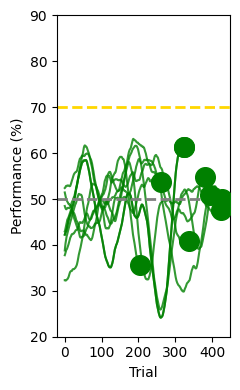

In [ ]:
plt.figure(figsize=(2.5,4))
for arr in all_correct_arr_sm:
    x = np.arange(len(arr))
    # get_acc_conv returns fraction (0-1); convert to % for plot
    pct = arr * 100
    plt.plot(x, pct, alpha=0.8, color='green')
    # large dot at end of each trace
    plt.scatter(x[-1], pct[-1], s=200, zorder=5, color='green')
plt.xlabel('Trial')
plt.ylabel('Performance (%)')
plt.ylim(20, 90)
# label every 100 trials on x axis
max_trials = max(len(arr) for arr in all_correct_arr)
plt.xticks(np.arange(0, max_trials + 1, 100))
plt.tight_layout()
plt.axhline(50, color='gray', linewidth=2, ls='--')
plt.axhline(70, color='gold', linewidth=2, ls='--')
plt.show()


In [ ]:
all_correct_arr = []
all_perf_by_mouse_trained = []

for paths in trained_paths_high_performance:
    perf = []
    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
        earlylick, correctarr, numtrials = s1.get_acc_conv(window=50)
        all_correct_arr.append(correctarr[:])
        perf.append(np.mean(correctarr))
    all_perf_by_mouse_trained.append(perf)

all_correct_arr_sm = smooth_traces(all_correct_arr, window=25)


Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 279
Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 151
Loading good trial inds from file
22 trials removed for stability reasons
only ppyr neurons: 232 --> 159
Loading good trial inds from file
33 trials removed for stability reasons
only ppyr neurons: 194 --> 150
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 287
Loading good trial inds from file
29 trials removed for stability reasons
only ppyr neurons: 484 --> 389
Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 192 --> 145
Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 417
Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 368 --> 302
Loading good trial inds from file
32 trials removed for 

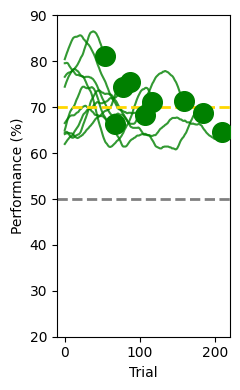

In [61]:
plt.figure(figsize=(2.5,4))
for arr in all_correct_arr_sm:
    x = np.arange(len(arr))
    # get_acc_conv returns fraction (0-1); convert to % for plot
    pct = arr * 100
    if pct[-1] < 62:
        x = x[:-50]
        pct = pct[:-50]
        continue
    plt.plot(x, pct, alpha=0.8, color='green')
    # large dot at end of each trace
    plt.scatter(x[-1], pct[-1], s=200, zorder=5, color='green')
plt.xlabel('Trial')
plt.ylabel('Performance (%)')
plt.ylim(20, 90)
# label every 100 trials on x axis
max_trials = max(len(arr) for arr in all_correct_arr)
plt.xticks(np.arange(0, max_trials + 1, 100))
plt.tight_layout()
plt.axhline(50, color='gray', linewidth=2, ls='--')
plt.axhline(70, color='gold', linewidth=2, ls='--')
plt.show()



In [77]:
all_perf_by_mouse_naive = []
for paths in naive_paths:
    perf = []
    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
        _, _,p = s1.performance_in_trials(s1.i_good_non_stim_trials)
        perf.append(p)
    all_perf_by_mouse_naive.append(perf)

all_perf_by_mouse_trained = []
for paths in trained_paths_high_performance:
    perf = []
    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
        _, _,p = s1.performance_in_trials(s1.i_good_non_stim_trials)
        perf.append(p)
    all_perf_by_mouse_trained.append(perf)

18 trials removed for stability reasons
only ppyr neurons: 333 --> 169
16 trials removed for stability reasons
only ppyr neurons: 299 --> 147
11 trials removed for stability reasons
only ppyr neurons: 225 --> 81
28 trials removed for stability reasons
only ppyr neurons: 270 --> 147
84 trials removed for stability reasons
only ppyr neurons: 268 --> 132
26 trials removed for stability reasons
only ppyr neurons: 241 --> 103
47 trials removed for stability reasons
only ppyr neurons: 295 --> 84
10 trials removed for stability reasons
only ppyr neurons: 295 --> 118
3 trials removed for stability reasons
only ppyr neurons: 310 --> 259
22 trials removed for stability reasons
only ppyr neurons: 422 --> 334
Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 279
Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 151
Loading good trial inds from file
22 trials removed for stability reasons
only ppyr

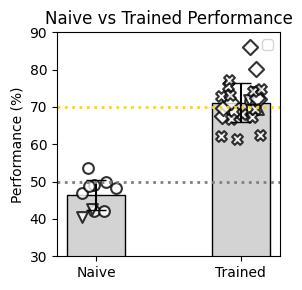

In [79]:
import matplotlib.pyplot as plt
import numpy as np

# Multiply all points by 100 (convert to percent)
all_perf_by_mouse_naive_pct = [[val * 100 for val in group] for group in all_perf_by_mouse_naive]
all_perf_by_mouse_trained_pct = [[val * 100 for val in group] for group in all_perf_by_mouse_trained]

# Calculate means for naive and trained groups (mean across all sublists)
naive_flat = [perf for group in all_perf_by_mouse_naive_pct for perf in group]
trained_flat = [perf for group in all_perf_by_mouse_trained_pct for perf in group]
means = [np.mean(naive_flat), np.mean(trained_flat)]
stds = [np.std(naive_flat), np.std(trained_flat)]

fig, ax = plt.subplots(figsize=(3, 3))

bar_colors = ['lightgrey', 'lightgrey']  # light grey for both bars
x_locs = [0, 0.5]
bar_width = 0.2  # thinner bars
labels = ['Naive', 'Trained']

# Plot bars with mean and std
ax.bar(
    x_locs,
    means,
    yerr=stds,
    color=bar_colors,
    width=bar_width,
    alpha=1,
    edgecolor='black',
    capsize=7,
    label='Mean $\pm$ SD'
)

# Markers for subgroups
marker_types = ['o', 'v', '^', 's', 'D', 'X', 'P', '*', '+', 'x']
# Scatter points for subgroups (each sublist gets a different marker)
for i, group in enumerate(all_perf_by_mouse_naive_pct):
    xs = np.full(len(group), x_locs[0]) + (np.random.rand(len(group))-0.5)*0.15  # jitter for visibility
    ax.scatter(
        xs, group,
        marker=marker_types[i % len(marker_types)],
        s=60,
        edgecolor='black',
        facecolor='white',
        linewidth=1.5,
        alpha=0.8,
        label=f'Naive {i+1}' if i==0 else None
    )

for i, group in enumerate(all_perf_by_mouse_trained_pct):
    xs = np.full(len(group), x_locs[1]) + (np.random.rand(len(group))-0.5)*0.15
    ax.scatter(
        xs, group,
        marker=marker_types[i % len(marker_types)],
        s=60,
        edgecolor='black',
        facecolor='white',
        linewidth=1.5,
        alpha=0.8,
        label=f'Trained {i+1}' if i==0 else None
    )

# Dotted lines at 50% (gray) and 70% (yellow)
ax.axhline(50, color='gray', linestyle=':', linewidth=2)
ax.axhline(70, color='gold', linestyle=':', linewidth=2)

ax.set_xticks(x_locs)
ax.set_xticklabels(labels)
ax.set_ylabel('Performance (%)')
ax.set_ylim(30, 90)
ax.set_title('Naive vs Trained Performance')

# Empty legend; comment out the following line if you want legend
ax.legend([],[])  

plt.tight_layout()
plt.savefig(r'P:\paperfigures\fig1\naive_vs_trained_performance.pdf')
plt.show()

## Example neurons

### No perturbations examples:

In [129]:
path = r'K:\data\CW84\python\2026_03_17'
s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)


Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 181


In [130]:
s1.get_epoch_selective(epoch=(s1.delay, s1.response ), p=0.0001)


[6, 11, 14, 16, 29, 41, 65, 73, 79, 101, 134, 148, 185, 207, 210]

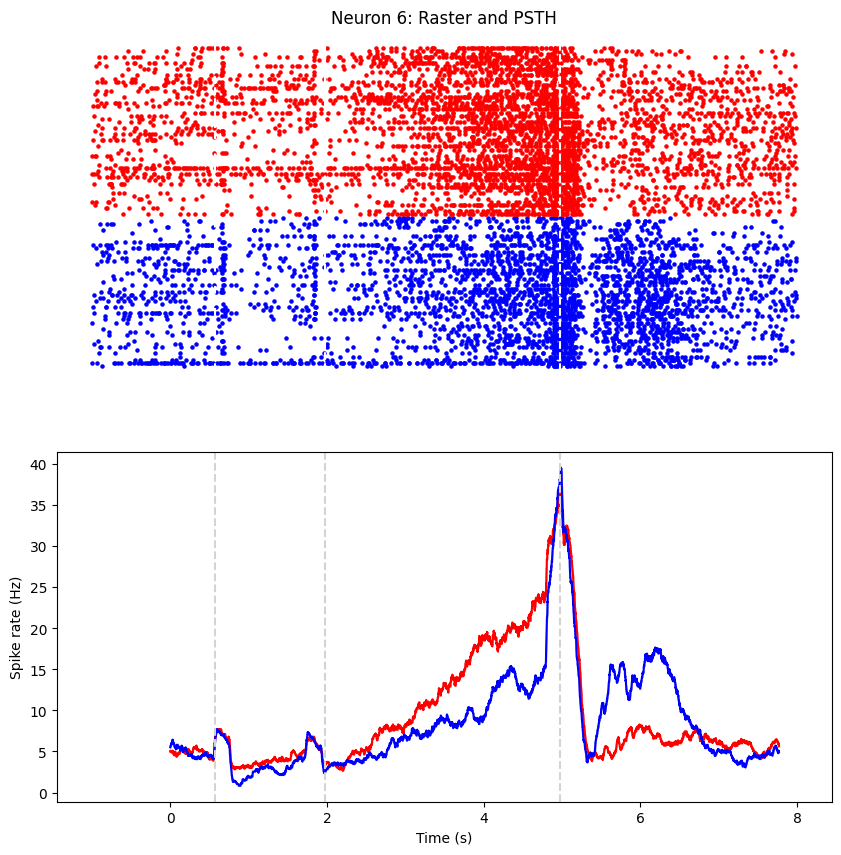

In [63]:
s1.plot_raster_and_PSTH(6, save=r'P:\paperfigures\fig1\exampleneuron1.pdf')

In [131]:
s1.get_epoch_selective(epoch=(s1.sample, s1.delay ), p=0.01)
185 in s1.R_alm_idx

True

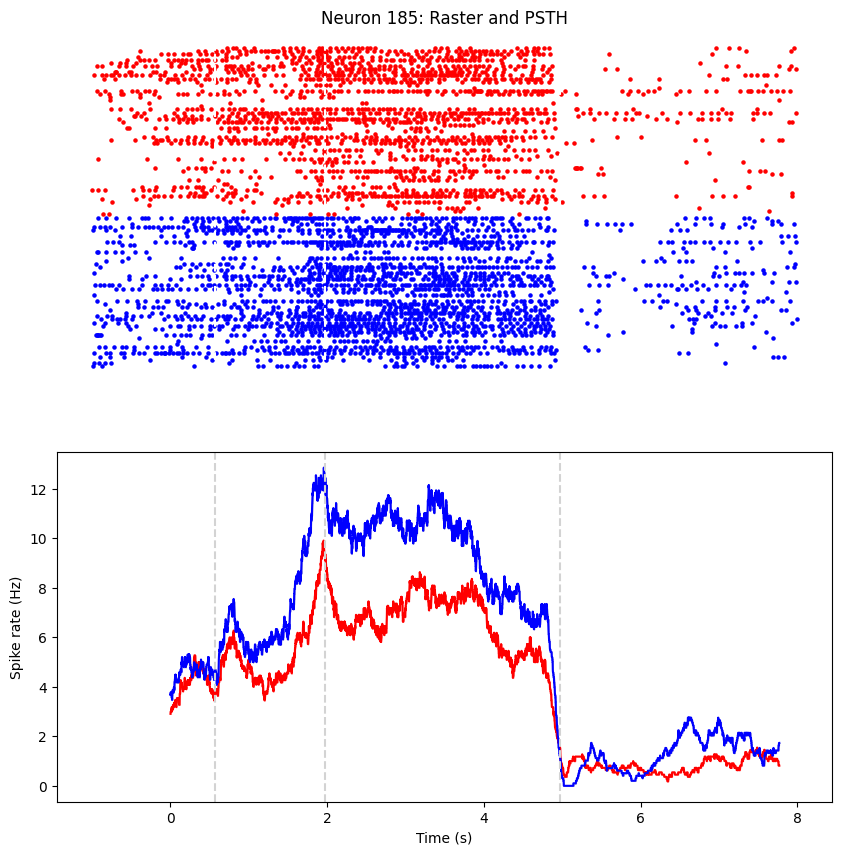

In [65]:
s1.plot_raster_and_PSTH(185, save=r'P:\paperfigures\fig1\exampleneuron2.pdf')

In [66]:
path = r'P:\data\CW92\python\2026_06_17'
s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
s1.get_epoch_selective(epoch=(s1.delay, s1.response ), p=0.0001)


Loading good trial inds from file
31 trials removed for stability reasons
only ppyr neurons: 289 --> 226


[1,
 15,
 34,
 51,
 67,
 71,
 84,
 88,
 104,
 105,
 106,
 107,
 115,
 125,
 127,
 129,
 131,
 145,
 159,
 160,
 165,
 169,
 216,
 229,
 230,
 233,
 239,
 286]

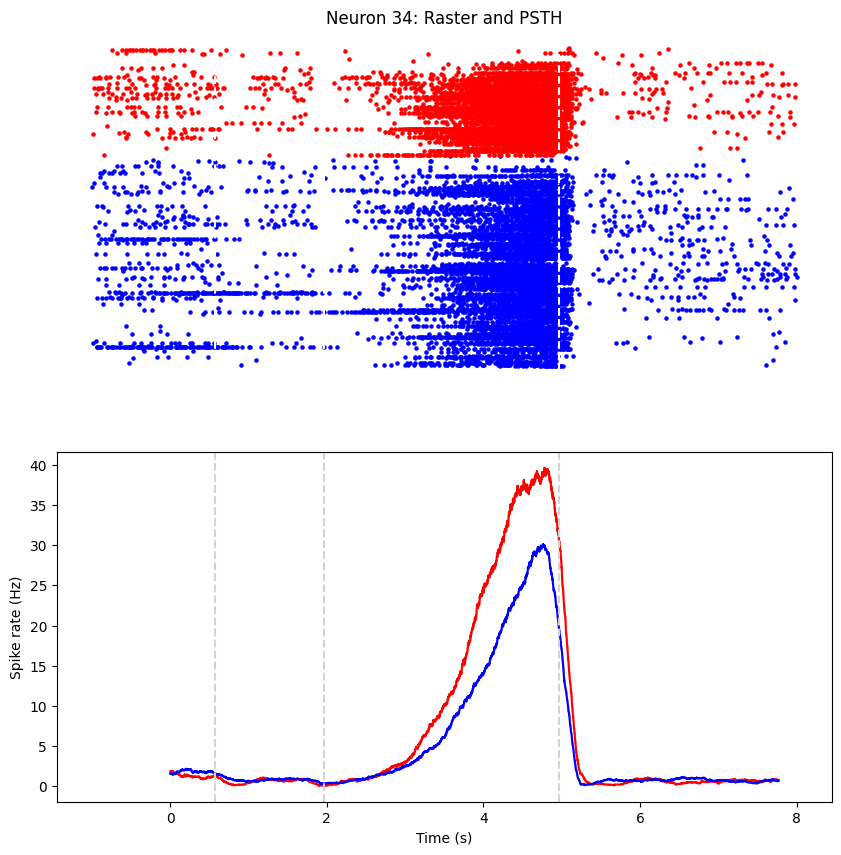

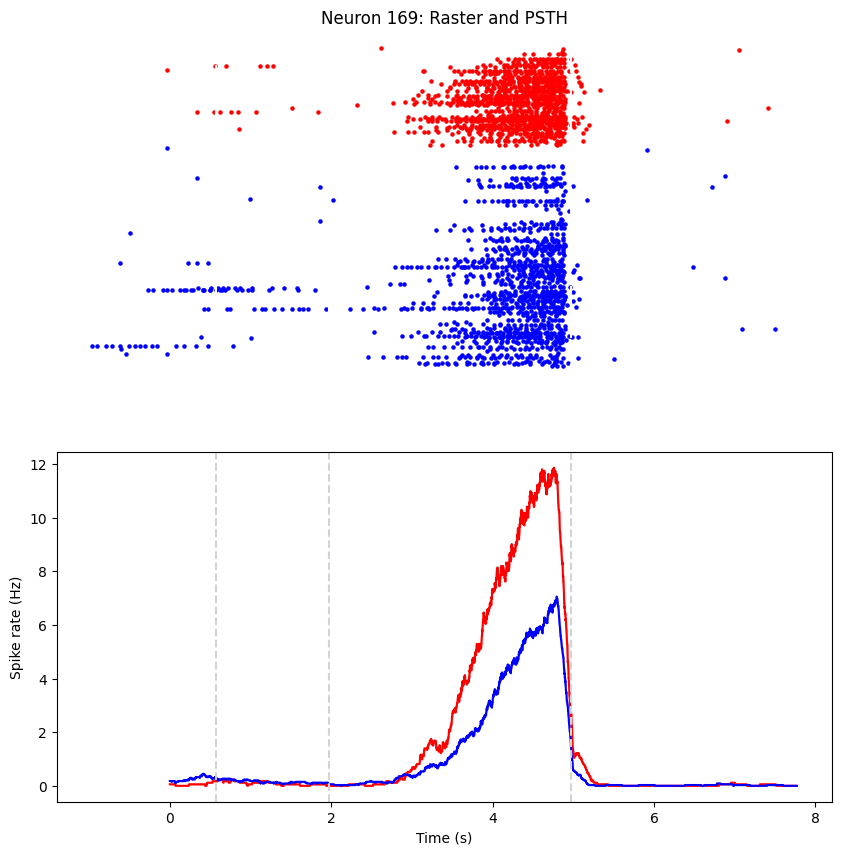

In [67]:
# for i in s1.get_epoch_selective(epoch=(s1.delay, s1.response ), p=0.0001):
s1.plot_raster_and_PSTH(34, save=r'P:\paperfigures\fig1\exampleneuron3.pdf')
s1.plot_raster_and_PSTH(169, save=r'P:\paperfigures\fig1\exampleneuron4.pdf')

Example naive neurons:

In [ ]:
path = r'M:\data\CW99\python\2026_05_09'
s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)
# s1.get_epoch_selective(epoch=(s1.delay, s1.response ), p=0.0001)


3 trials removed for stability reasons
only ppyr neurons: 310 --> 259


True

In [134]:
109 in s1.R_alm_idx

False

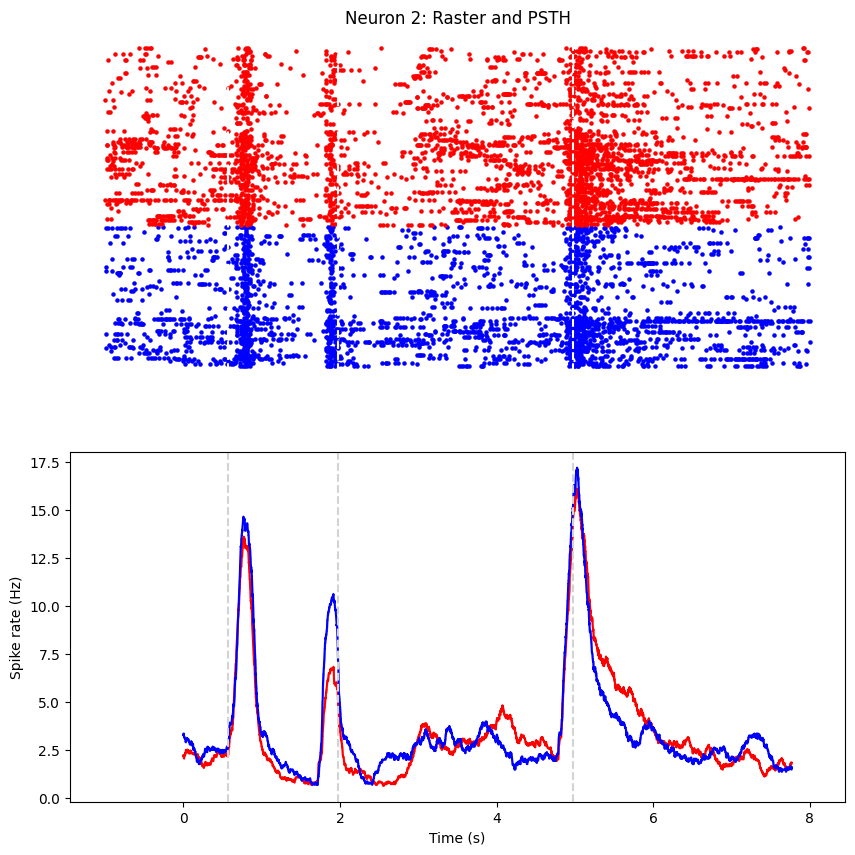

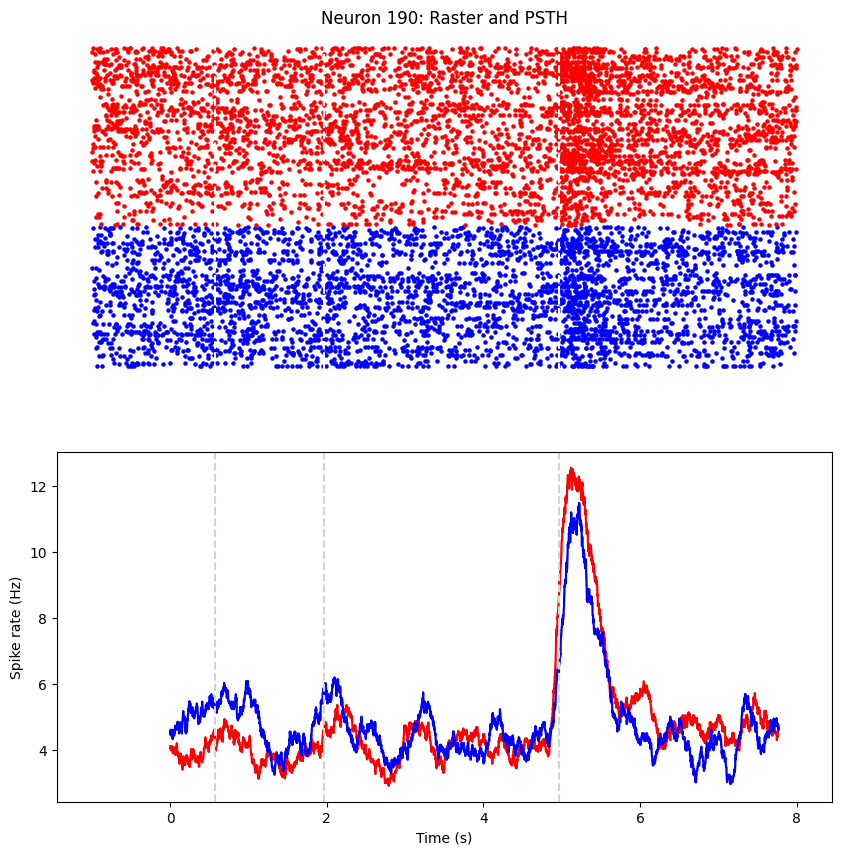

In [135]:
s1.plot_raster_and_PSTH(2, save=r'P:\paperfigures\fig1\naive_example_neuron_1.pdf') # Left example
s1.plot_raster_and_PSTH(190, save=r'P:\paperfigures\fig1\naive_example_neuron_2.pdf') # Right example


### Example neurons with perturbation

In [68]:
from ephysSession import Session

path = r'K:\data\CW84\python\2026_03_14'
s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)

s1.get_epoch_selective(epoch=(s1.delay, s1.response ), p=0.0001)


Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 192 --> 145


[15, 39, 41, 47, 62, 67, 83, 84, 128, 152]

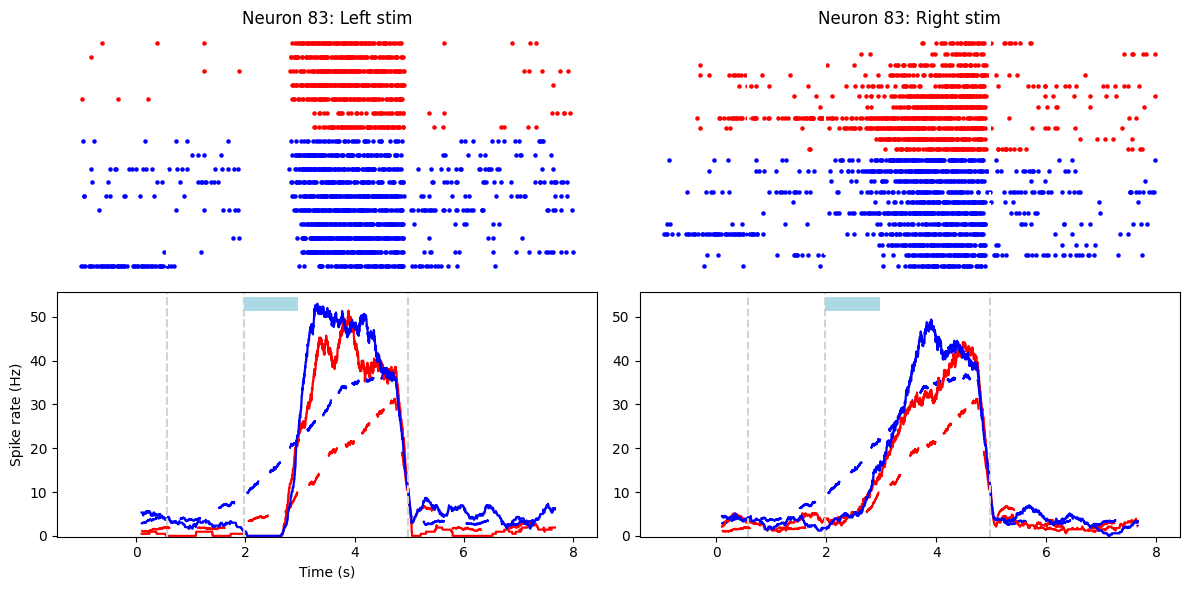

In [70]:
s1.plot_raster_and_PSTH(83, opto=True, stimside = 'both', stim_only=True, binsize=300, timestep=50, save=r'P:\paperfigures\fig1\stim_exampleneuron1.pdf')

In [71]:
path = r'K:\data\CW84\python\2026_03_17'
s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)

s1.get_epoch_selective(epoch=(s1.delay, s1.response ), p=0.0001)



Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 181


[6, 11, 14, 16, 29, 41, 65, 73, 79, 101, 134, 148, 185, 207, 210]

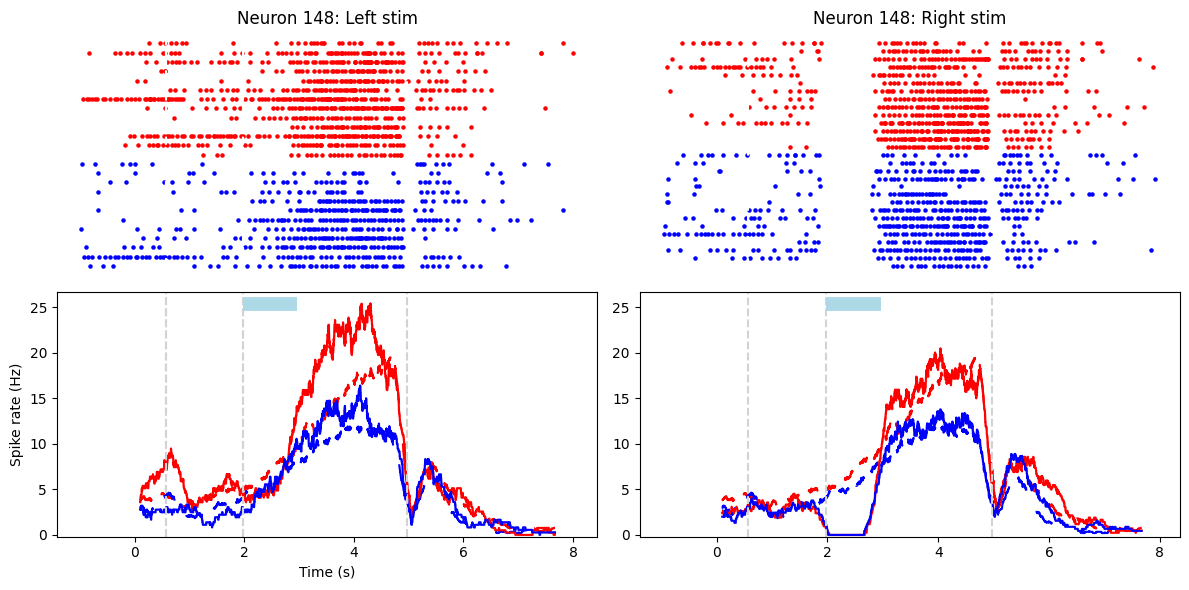

In [73]:
s1.plot_raster_and_PSTH(148, opto=True, stimside = 'both', stim_only=True, binsize=300, timestep=50, save=r'P:\paperfigures\fig1\stim_exampleneuron3.pdf')

## Heatmap of selectivity

In [126]:
# Expert neurons
p=0.001

all_sel_traces_expert_sample = []
all_sel_traces_expert_delay = []
all_sel_traces_expert_response = []

binsize=250
timestep=50

for path in cat(trained_paths_high_performance):

    s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    sample_epoch = (s1.sample, s1.delay)
    delay_epoch = (s1.delay+1, s1.response)
    response_epoch = (s1.response, s1.response + 2)

    L_correct_idx = s1.lick_correct_direction('l')
    R_correct_idx = s1.lick_correct_direction('r')

    expert_sample_sel, tstat_sample = s1.get_epoch_selective(sample_epoch, p=p, return_stat=True)

    expert_delay_sel, tstat_delay = s1.get_epoch_selective(delay_epoch, p=p, return_stat=True)
    tstat_delay = [tstat_delay[n] for n in range(len(tstat_delay)) if expert_delay_sel[n] not in expert_sample_sel]
    expert_delay_sel = [n for n in expert_delay_sel if n not in expert_sample_sel]

    expert_response_sel, tstat_response = s1.get_epoch_selective(response_epoch, p=p, return_stat=True)
    tstat_response = [tstat_response[n] for n in range(len(tstat_response)) if expert_response_sel[n] not in expert_sample_sel and expert_response_sel[n] not in expert_delay_sel]
    expert_response_sel = [n for n in expert_response_sel if n not in expert_sample_sel and n not in expert_delay_sel]


    # Sample

    tstatidx = np.where(np.array(tstat_sample) > 0)[0]
    l_neurons = np.array(expert_sample_sel)[tstatidx]
    if len(l_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_sample.append(L_traces - R_traces)

    tstatidx = np.where(np.array(tstat_sample) < 0)[0]
    r_neurons = np.array(expert_sample_sel)[tstatidx]
    if len(r_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_sample.append(R_traces - L_traces)

    # Delay
    tstatidx = np.where(np.array(tstat_delay) > 0)[0]
    l_neurons = np.array(expert_delay_sel)[tstatidx]
    if len(l_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_delay.append(L_traces - R_traces)

    tstatidx = np.where(np.array(tstat_delay) < 0)[0]
    r_neurons = np.array(expert_delay_sel)[tstatidx]
    if len(r_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_delay.append(R_traces - L_traces)

    # Response
    tstatidx = np.where(np.array(tstat_response) > 0)[0]
    l_neurons = np.array(expert_response_sel)[tstatidx]
    if len(l_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_response.append(L_traces - R_traces)

    tstatidx = np.where(np.array(tstat_response) < 0)[0]
    r_neurons = np.array(expert_response_sel)[tstatidx]
    if len(r_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_response.append(R_traces - L_traces)



    



Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 279
Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 151
Loading good trial inds from file
22 trials removed for stability reasons
only ppyr neurons: 232 --> 159
Loading good trial inds from file
33 trials removed for stability reasons
only ppyr neurons: 194 --> 150
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 287
Loading good trial inds from file
29 trials removed for stability reasons
only ppyr neurons: 484 --> 389
Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 192 --> 145
Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 417
Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 368 --> 302
Loading good trial inds from file
32 trials removed for 

In [127]:
all_sel_traces_expert_sample_mod = np.vstack([
    item
    for item in all_sel_traces_expert_sample
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])

all_sel_traces_expert_delay_mod = np.vstack([       
    item
    for item in all_sel_traces_expert_delay
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])

all_sel_traces_expert_response_mod = np.vstack([    
    item
    for item in all_sel_traces_expert_response
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])


In [128]:
all_sel_traces_expert_response_mod.shape

(1464, 7670)

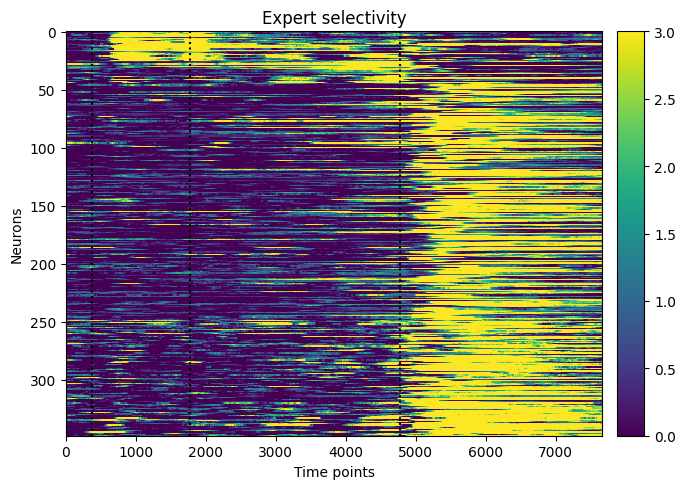

In [110]:
expert_r_pref = (np.vstack([all_sel_traces_expert_sample_mod, all_sel_traces_expert_delay_mod, all_sel_traces_expert_response_mod]))
# Optionally keep naive_r_pref and learning_r_pref calculation if you want, but only plot expert!

# Plot expert_r_pref as a heatmap with all rows shown and aspect ratio optimized for "squareness"
num_rows, num_cols = expert_r_pref.shape
expert_r_pref_display = expert_r_pref #[:, col_start:]

# Make the plot much more "compressed" vertically, stretched in x,
# resembling a ~5x6 rectangle (wider than it is tall)
fig_width, fig_height = 8, 5  # preserve the look of the original
fig, ax = plt.subplots(1, 1, figsize=(fig_width, fig_height))

# vmin/vmax and aspect for single panel
vmin, vmax = 0, 3
cmap = 'viridis'
aspect = 'auto'

# Plot Expert only
im = ax.imshow(
    expert_r_pref_display,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    aspect=aspect,
    interpolation='nearest'
)
ax.set_title("Expert selectivity")
ax.set_xlabel("Time points")
ax.set_ylabel("Neurons")

# Draw thick vertical black dotted lines at s1.sample, s1.delay, s1.response locations
event_times = [np.where(time > s1.sample)[0][0], np.where(time > s1.delay)[0][0], np.where(time > s1.response)[0][0]]
for t in event_times:
    ax.axvline(t, color='k', linestyle=':', linewidth=1.5, alpha=1.0)

# Move colorbar to the far right, match style
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.15)
plt.subplots_adjust(right=0.88)  # to make sure the colorbar fits at the side

cbar = fig.colorbar(im, cax=cax, orientation='vertical')
plt.tight_layout(rect=[0, 0, 0.87, 1])  # leave room for colorbar
# plt.savefig(r'P:\paperfigures\fig1\expert_selectivity.pdf')
plt.show()


In [87]:
# Naive neurons
p=0.001

all_sel_traces_expert_sample = []
all_sel_traces_expert_delay = []
all_sel_traces_expert_response = []

binsize=250
timestep=50

for path in cat(naive_paths):

    s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
    sample_epoch = (s1.sample, s1.delay)
    delay_epoch = (s1.delay+1, s1.response)
    response_epoch = (s1.response, s1.response + 2)

    L_correct_idx = s1.lick_correct_direction('l')
    R_correct_idx = s1.lick_correct_direction('r')

    if 'CW48' not in path:
        L_correct_idx = [n for n in L_correct_idx if not s1.stim_ON[n]]
        R_correct_idx = [n for n in R_correct_idx if not s1.stim_ON[n]]

    expert_sample_sel, tstat_sample = s1.get_epoch_selective(sample_epoch, p=p, return_stat=True)

    expert_delay_sel, tstat_delay = s1.get_epoch_selective(delay_epoch, p=p, return_stat=True)
    tstat_delay = [tstat_delay[n] for n in range(len(tstat_delay)) if expert_delay_sel[n] not in expert_sample_sel]
    expert_delay_sel = [n for n in expert_delay_sel if n not in expert_sample_sel]

    expert_response_sel, tstat_response = s1.get_epoch_selective(response_epoch, p=p, return_stat=True)
    tstat_response = [tstat_response[n] for n in range(len(tstat_response)) if expert_response_sel[n] not in expert_sample_sel and expert_response_sel[n] not in expert_delay_sel]
    expert_response_sel = [n for n in expert_response_sel if n not in expert_sample_sel and n not in expert_delay_sel]


    # Sample

    tstatidx = np.where(np.array(tstat_sample) > 0)[0]
    l_neurons = np.array(expert_sample_sel)[tstatidx]
    if len(l_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_sample.append(L_traces - R_traces)

    tstatidx = np.where(np.array(tstat_sample) < 0)[0]
    r_neurons = np.array(expert_sample_sel)[tstatidx]
    if len(r_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_sample.append(R_traces - L_traces)

    # Delay
    tstatidx = np.where(np.array(tstat_delay) > 0)[0]
    l_neurons = np.array(expert_delay_sel)[tstatidx]
    if len(l_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_delay.append(L_traces - R_traces)

    tstatidx = np.where(np.array(tstat_delay) < 0)[0]
    r_neurons = np.array(expert_delay_sel)[tstatidx]
    if len(r_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_delay.append(R_traces - L_traces)

    # Response
    tstatidx = np.where(np.array(tstat_response) > 0)[0]
    l_neurons = np.array(expert_response_sel)[tstatidx]
    if len(l_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(l_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(l_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_response.append(L_traces - R_traces)

    tstatidx = np.where(np.array(tstat_response) < 0)[0]
    r_neurons = np.array(expert_response_sel)[tstatidx]
    if len(r_neurons) > 0:
        L_traces, time, _ = s1.get_PSTH_multiple(r_neurons, L_correct_idx, binsize=binsize, timestep=timestep)
        R_traces, time, _ = s1.get_PSTH_multiple(r_neurons, R_correct_idx, binsize=binsize, timestep=timestep)
        all_sel_traces_expert_response.append(R_traces - L_traces)



    



Remove 128 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 333 --> 171
Remove 143 trials from session for bad behavior
16 trials removed for stability reasons
only ppyr neurons: 299 --> 123
Remove 130 trials from session for bad behavior
8 trials removed for stability reasons
only ppyr neurons: 225 --> 92
Remove 186 trials from session for bad behavior
11 trials removed for stability reasons
only ppyr neurons: 270 --> 156
Remove 189 trials from session for bad behavior
54 trials removed for stability reasons
only ppyr neurons: 268 --> 134
Remove 189 trials from session for bad behavior
22 trials removed for stability reasons
only ppyr neurons: 241 --> 125
Remove 114 trials from session for bad behavior
21 trials removed for stability reasons
only ppyr neurons: 295 --> 86
Remove 57 trials from session for bad behavior
10 trials removed for stability reasons
only ppyr neurons: 295 --> 120
Remove 126 trials from session for bad behavior
3 tri

In [88]:
all_sel_traces_expert_sample_mod = np.vstack([
    item
    for item in all_sel_traces_expert_sample
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])

all_sel_traces_expert_delay_mod = np.vstack([       
    item
    for item in all_sel_traces_expert_delay
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])

all_sel_traces_expert_response_mod = np.vstack([    
    item
    for item in all_sel_traces_expert_response
    if isinstance(item, (list, np.ndarray)) and len(item) > 0
])


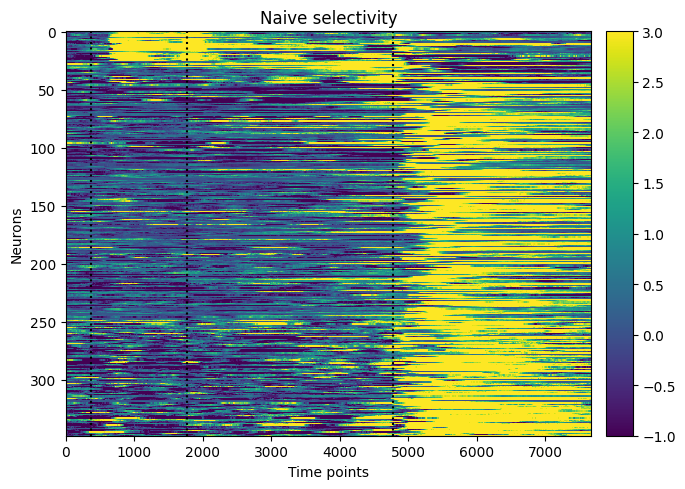

In [109]:
expert_r_pref = (np.vstack([all_sel_traces_expert_sample_mod, all_sel_traces_expert_delay_mod, all_sel_traces_expert_response_mod]))
# Optionally keep naive_r_pref and learning_r_pref calculation if you want, but only plot expert!

# Plot expert_r_pref as a heatmap with all rows shown and aspect ratio optimized for "squareness"
num_rows, num_cols = expert_r_pref.shape
expert_r_pref_display = expert_r_pref #[:, col_start:]

# Make the plot much more "compressed" vertically, stretched in x,
# resembling a ~5x6 rectangle (wider than it is tall)
fig_width, fig_height = 8, 5  # preserve the look of the original
fig, ax = plt.subplots(1, 1, figsize=(fig_width, fig_height))

# vmin/vmax and aspect for single panel
vmin, vmax = -1, 3
cmap = 'viridis'
aspect = 'auto'

# Plot Expert only
im = ax.imshow(
    expert_r_pref_display,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    aspect=aspect,
    interpolation='nearest'
)
ax.set_title("Naive selectivity")
ax.set_xlabel("Time points")
ax.set_ylabel("Neurons")

# Draw thick vertical black dotted lines at s1.sample, s1.delay, s1.response locations
event_times = [np.where(time > s1.sample)[0][0], np.where(time > s1.delay)[0][0], np.where(time > s1.response)[0][0]]
for t in event_times:
    ax.axvline(t, color='k', linestyle=':', linewidth=1.5, alpha=1.0)

# Move colorbar to the far right, match style
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.15)
plt.subplots_adjust(right=0.88)  # to make sure the colorbar fits at the side

cbar = fig.colorbar(im, cax=cax, orientation='vertical')
plt.tight_layout(rect=[0, 0, 0.87, 1])  # leave room for colorbar
# plt.savefig(r'P:\paperfigures\fig1\naive_selectivity.pdf')
plt.show()


### Selectivity modularity


Example FOV

In [117]:
def plot_selectivity_recovery(s1, left_info, right_info, save=False):
    sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
    sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
    
    f, axarr = plt.subplots(2,2, sharey='row', figsize=(12,10))  
    axarr[0,0].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)
    axarr[1,1].axvspan(s1.delay, s1.delay+1, color='lightblue', alpha=0.6)

    for i in range(2):
        axarr[i,0].plot(time, sel, 'black')
                
        axarr[i,0].fill_between(time, sel - err, 
                  sel + err,
                  color=['darkgray'])
    
        axarr[i,1].plot(time, sel_R, 'black')
                
        axarr[i,1].fill_between(time, sel_R - err_R, 
                  sel_R + err_R,
                  color=['darkgray'])
        
    axarr[0,0].plot(time, selo_stimleft, 'blue')
            
    axarr[0,0].fill_between(time, selo_stimleft - erro_stimleft, 
              selo_stimleft + erro_stimleft,
              color=['lightblue'])       
    axarr[0,0].hlines(y=max(cat((selo_stimleft, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[1,0].plot(time, selo_stimright, 'blue')
            
    axarr[1,0].fill_between(time, selo_stimright - erro_stimright, 
              selo_stimright + erro_stimright,
              color=['lightblue'])      
    axarr[1,0].hlines(y=max(cat((selo_stimright, sel))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    axarr[0,1].plot(time, selo_stimleft_R, 'blue')
            
    axarr[0,1].fill_between(time, selo_stimleft_R - erro_stimleft_R, 
              selo_stimleft_R + erro_stimleft_R,
              color=['lightblue'])       
    axarr[0,1].hlines(y=max(cat((selo_stimleft_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    axarr[1,1].plot(time, selo_stimright_R, 'blue')
            
    axarr[1,1].fill_between(time, selo_stimright_R - erro_stimright_R, 
              selo_stimright_R + erro_stimright_R,
              color=['lightblue'])      
    axarr[1,1].hlines(y=max(cat((selo_stimright_R, sel_R))), xmin=s1.delay, xmax=s1.delay+1, linewidth=10, color='blue')
    
    
    
    for i in range(2):
        for j in range(2):
            axarr[i,j].axvline(s1.sample, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.delay, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axvline(s1.response, color = 'grey', alpha=0.5, ls = '--')
            axarr[i,j].axhline(0, color = 'grey', alpha=0.5, ls = '--')
    
    left_sel_n, right_sel_n = len([n for n in s1.selective_neurons if n in s1.L_alm_idx]), len([n for n in s1.selective_neurons if n in s1.R_alm_idx])
    axarr[0,0].set_title('Left ALM (n={})'.format(left_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[0,1].set_title('Right ALM (n={})'.format(right_sel_n)) # (n = {} neurons)'.format(num_neurons))                  
    axarr[1,0].set_xlabel('Time from Go cue (s)')
    axarr[0,0].set_ylabel('Selectivity')
    
    # plt.suptitle('{} ALM recording ({} neurons)'.format(s1.side, len(all_control_sel)))
    # axarr[0,0].set_ylim(-5,15)
    axarr[0,0].set_ylim(bottom=-2)
    axarr[1,1].set_ylim(bottom=-2)

    if save:
        plt.savefig(save)

    plt.show()

Loading good trial inds from file
26 trials removed for stability reasons
only ppyr neurons: 233 --> 186


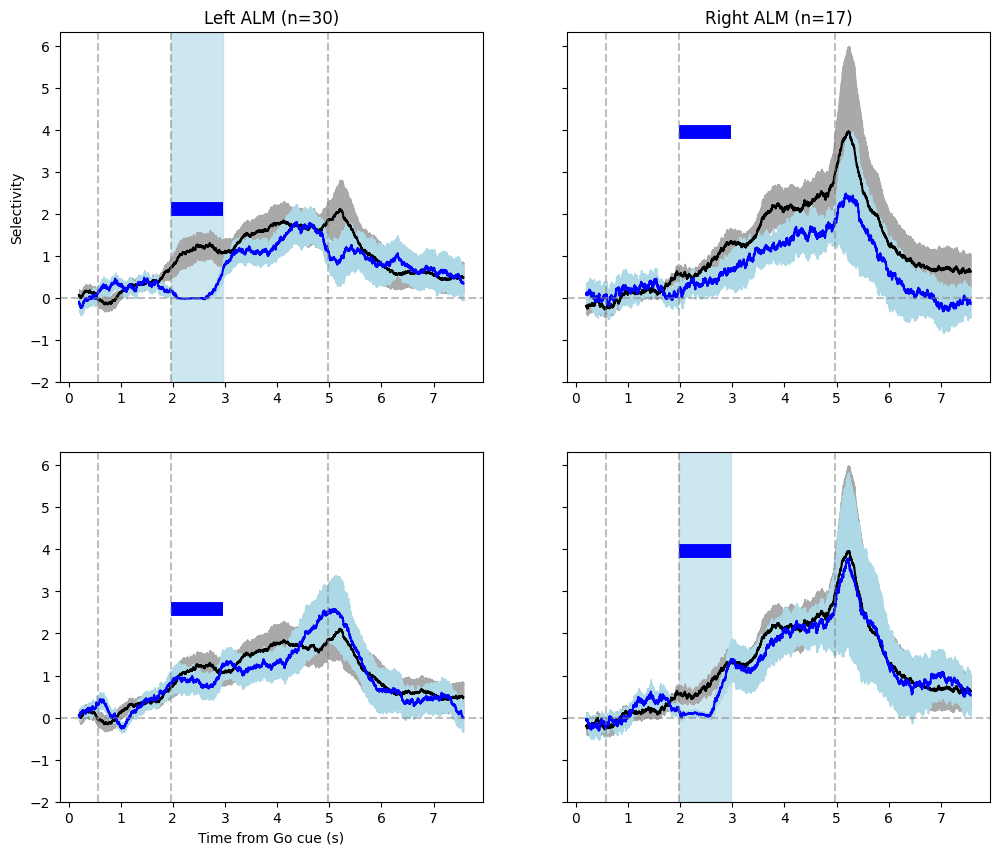

In [118]:
# modular FOV - still need one
path =  r'P:\data\CW92\python\2026_06_21' # Modular FOV
# path = r'L:\data\CW68\python\2025_12_15'
# path = r'K:\data\CW85\python\2026_02_07'
s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info, save=r'P:\paperfigures\fig1\modular_FOV.pdf')

Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 280


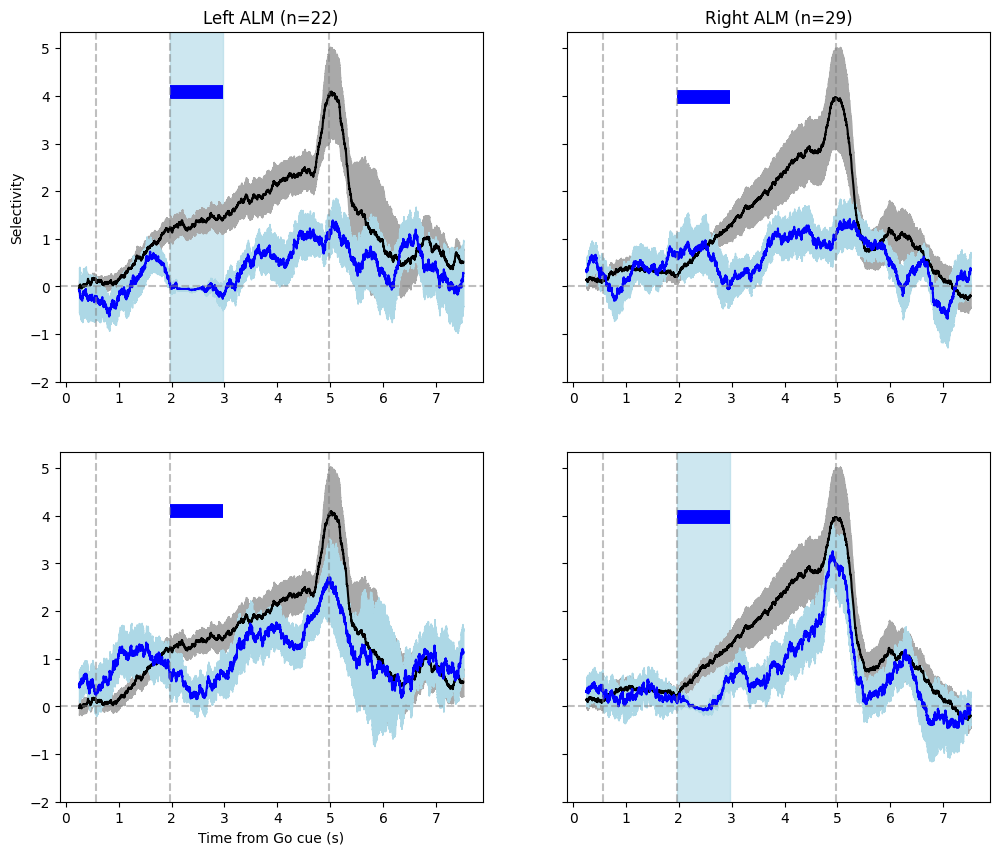

In [124]:
# L dominant FOV
path = r'K:\data\CW84\python\2026_03_14' # Rdom
path = r'K:\data\CW84\python\2026_03_19' # L DOM
# path =  r'P:\data\CW92\python\2026_06_24' # Modular FOV

s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01, 
                                                    binsize=450, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)#,save=r'P:\paperfigures\fig1\Ldom_fov.pdf')

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


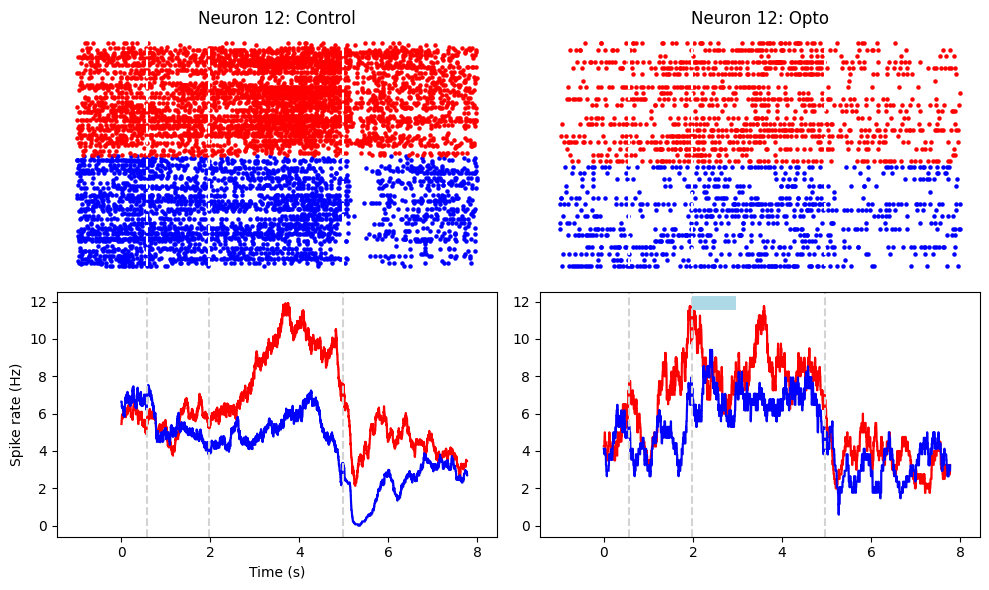

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


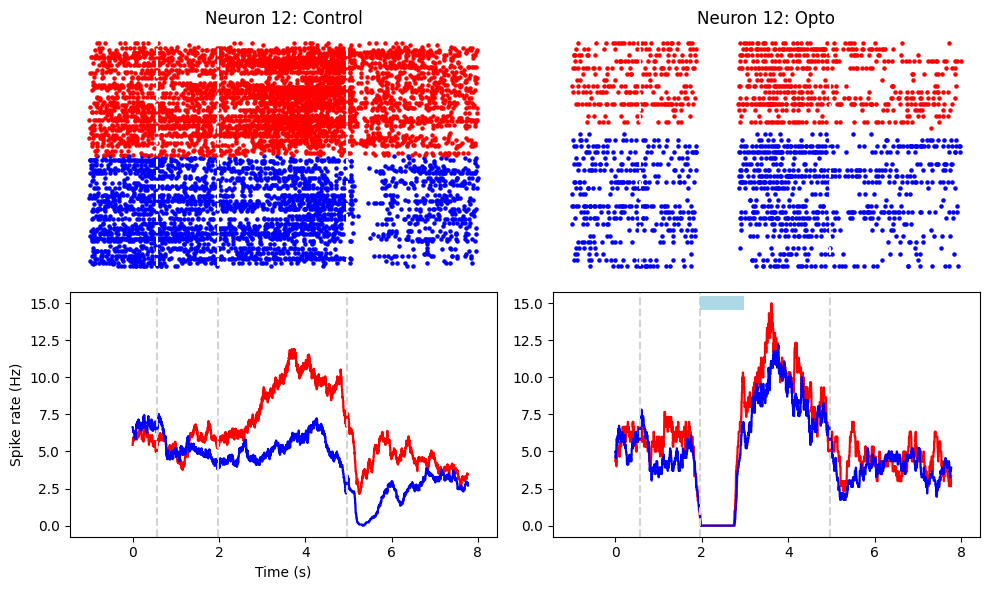

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


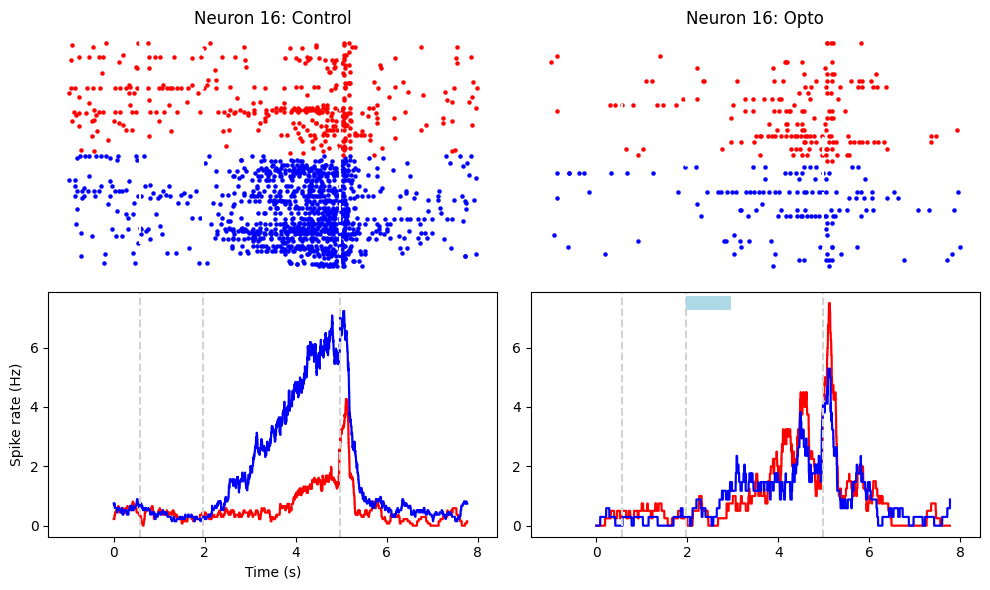

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


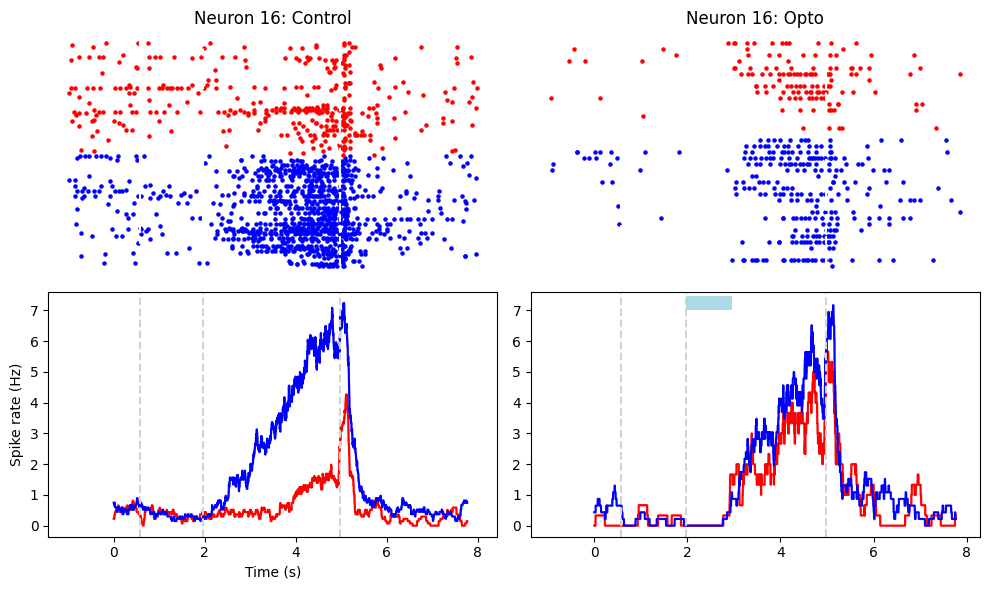

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


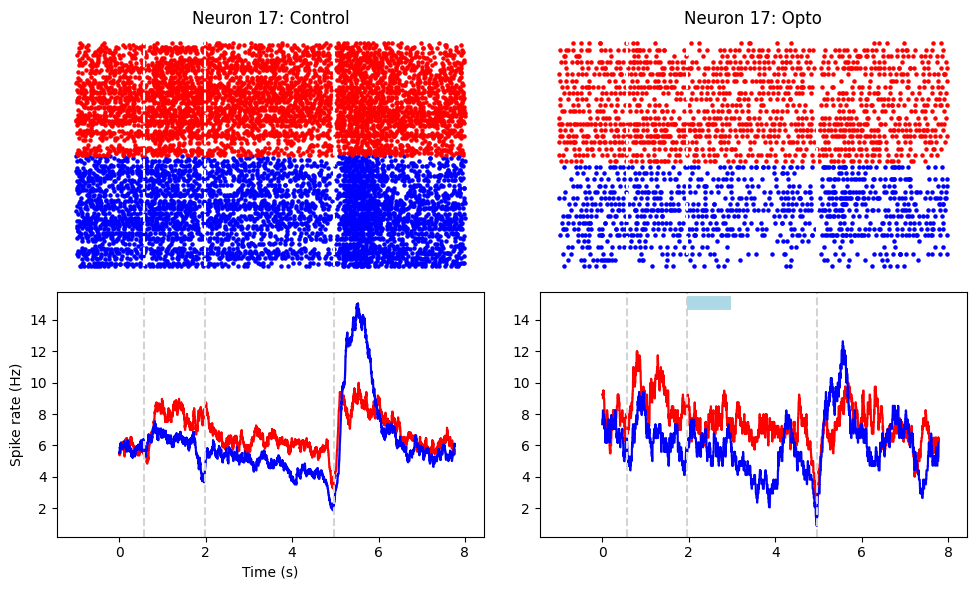

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


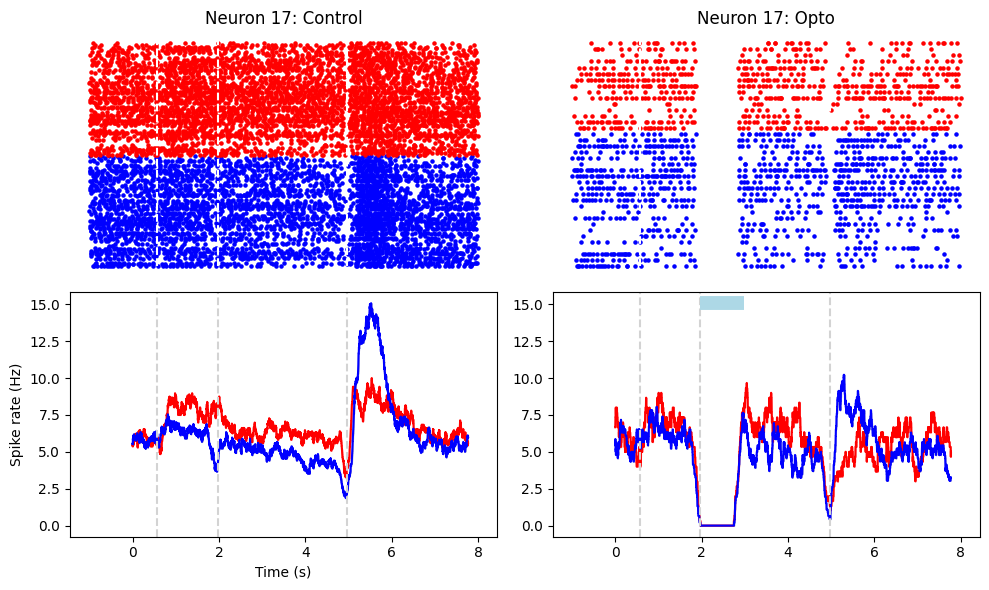

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


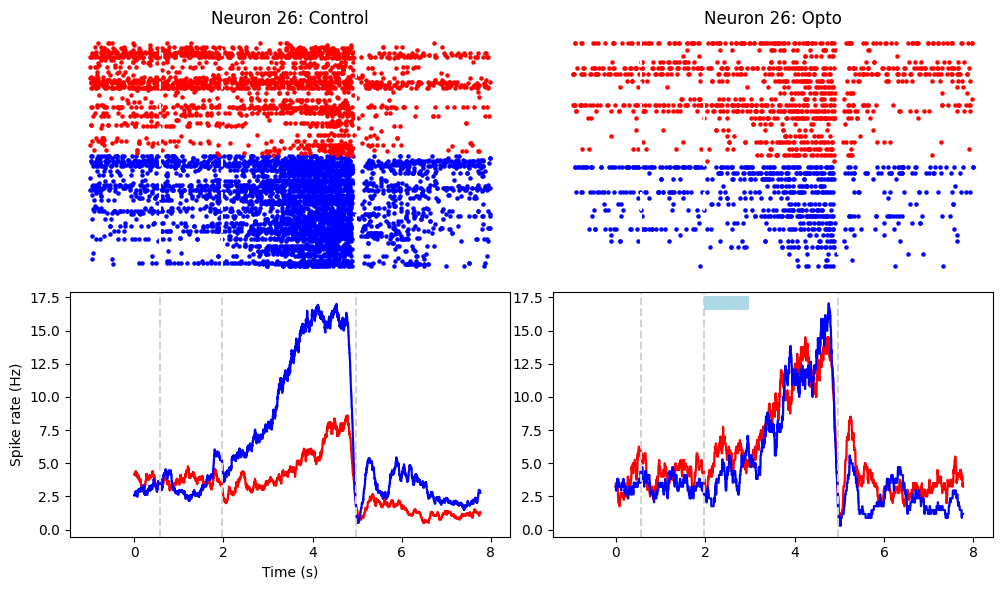

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


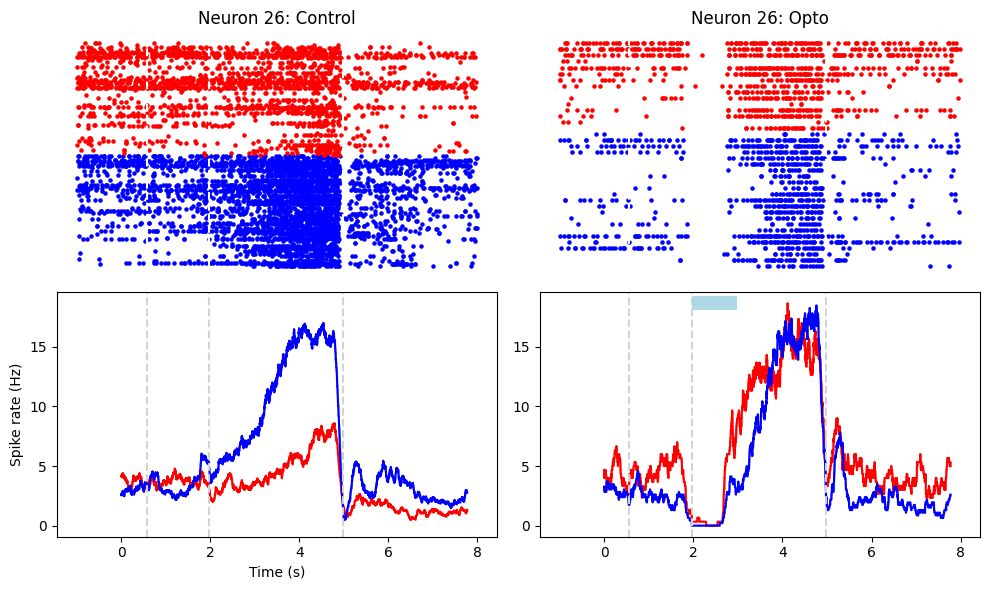

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


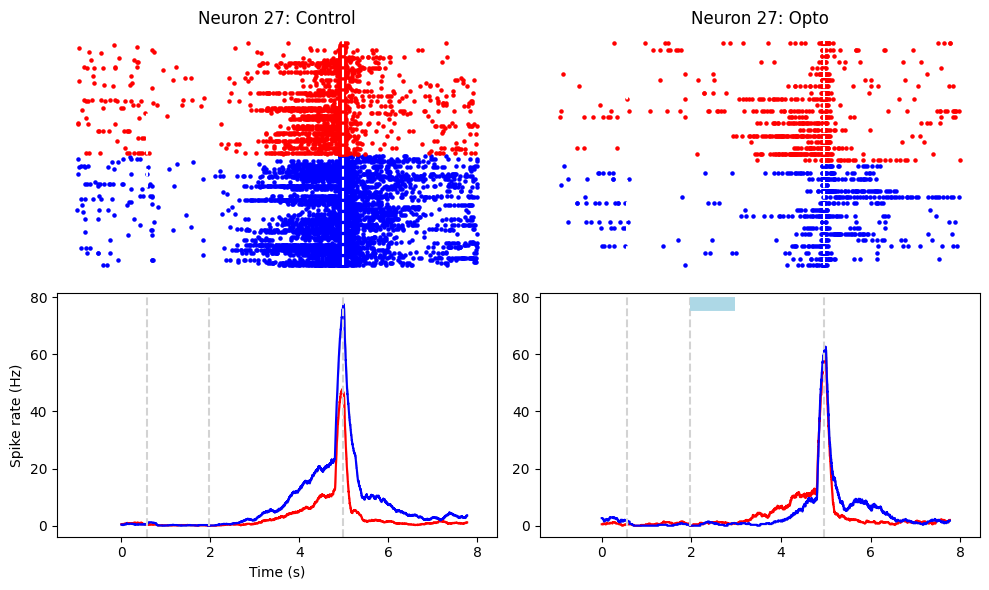

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


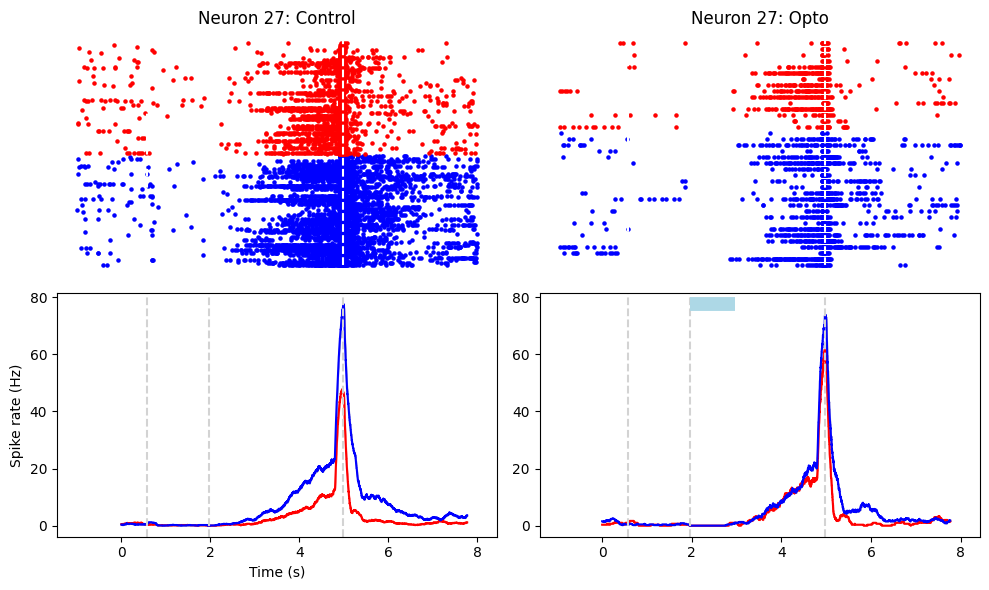

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


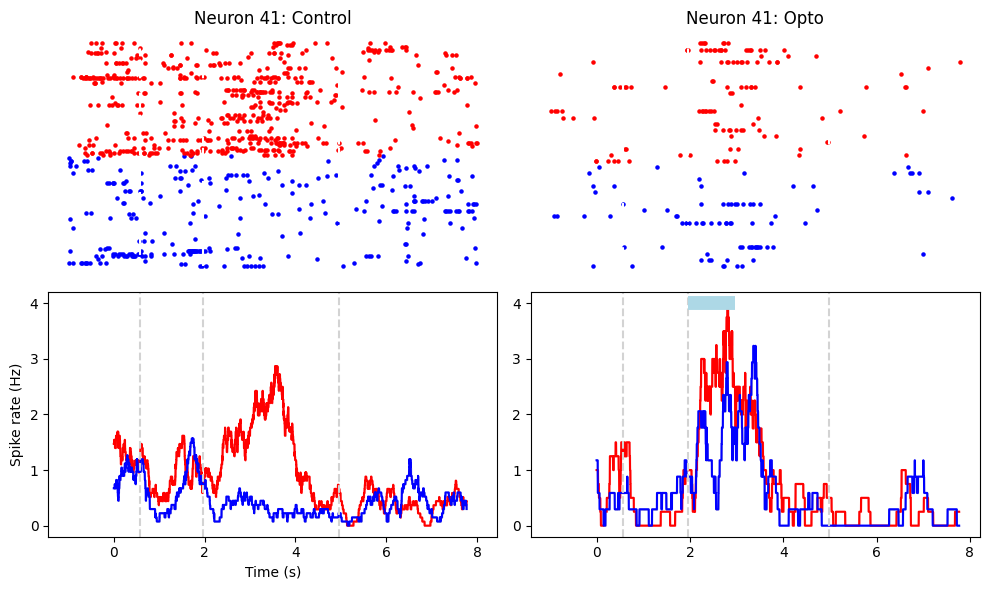

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


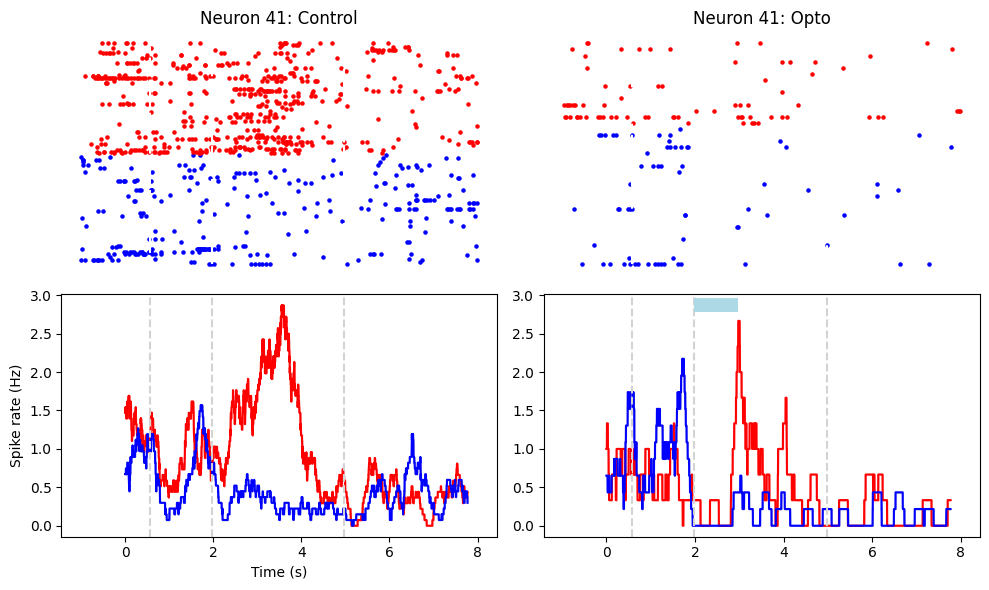

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


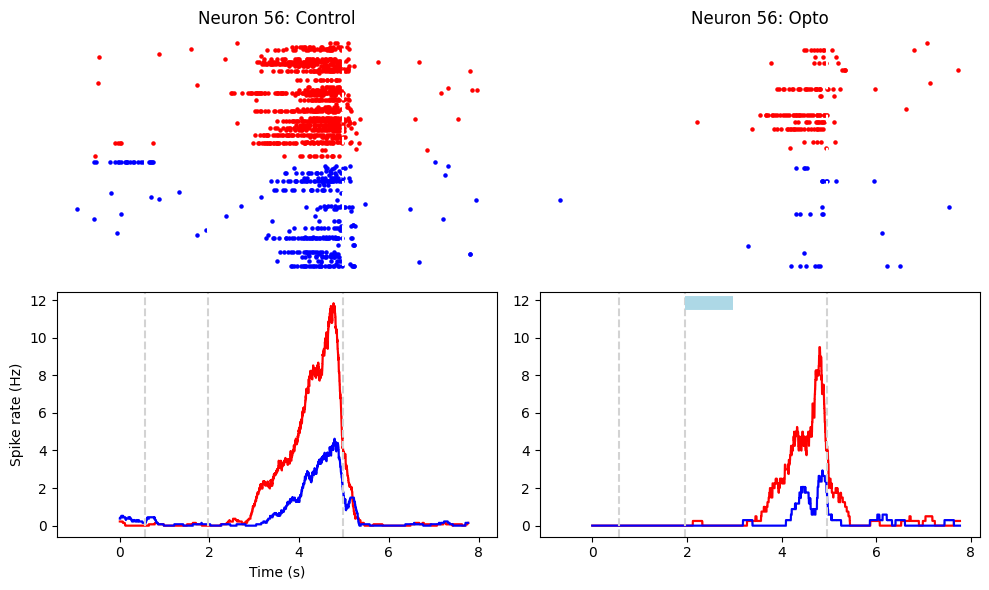

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


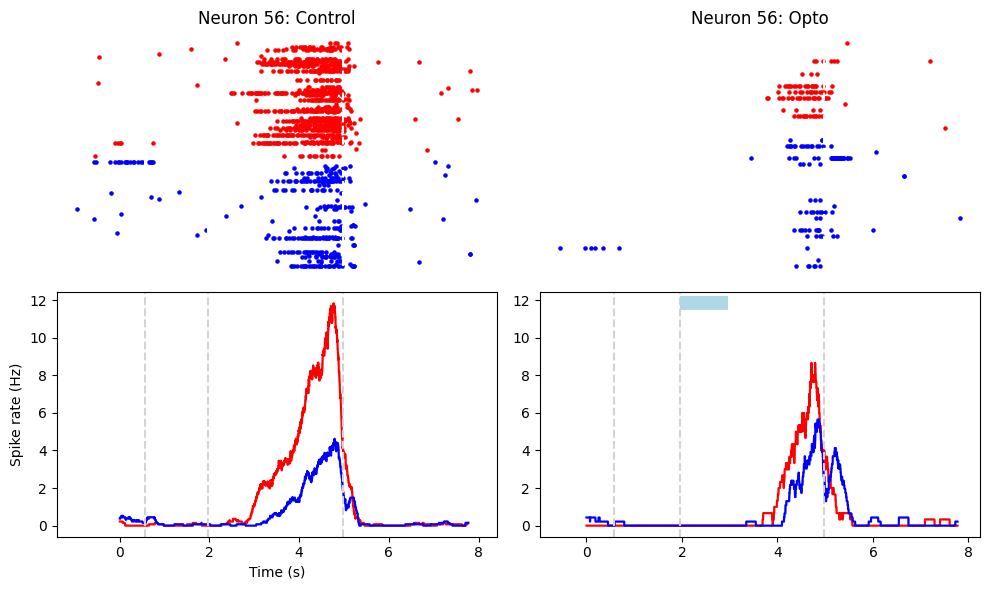

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


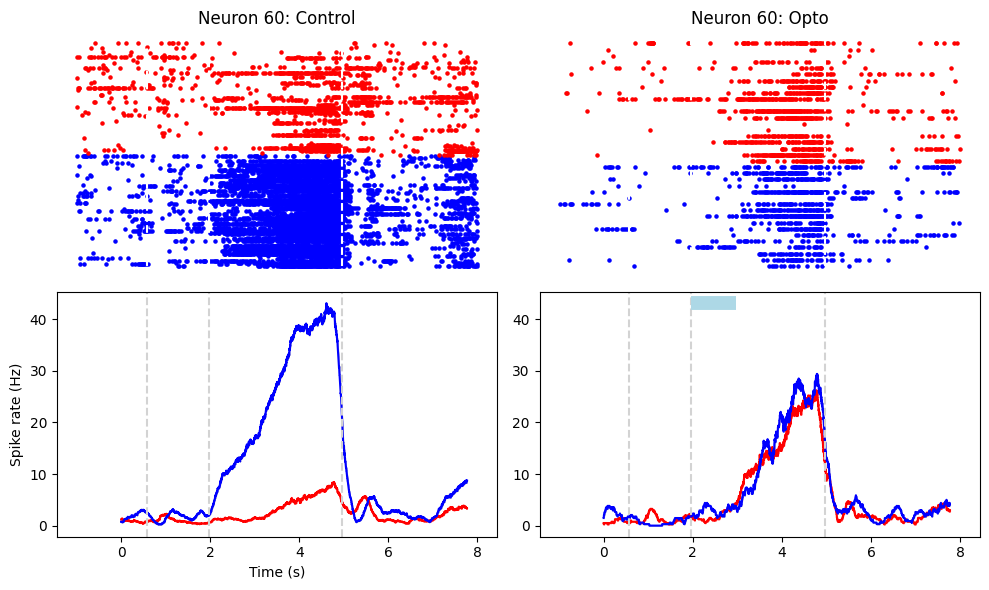

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


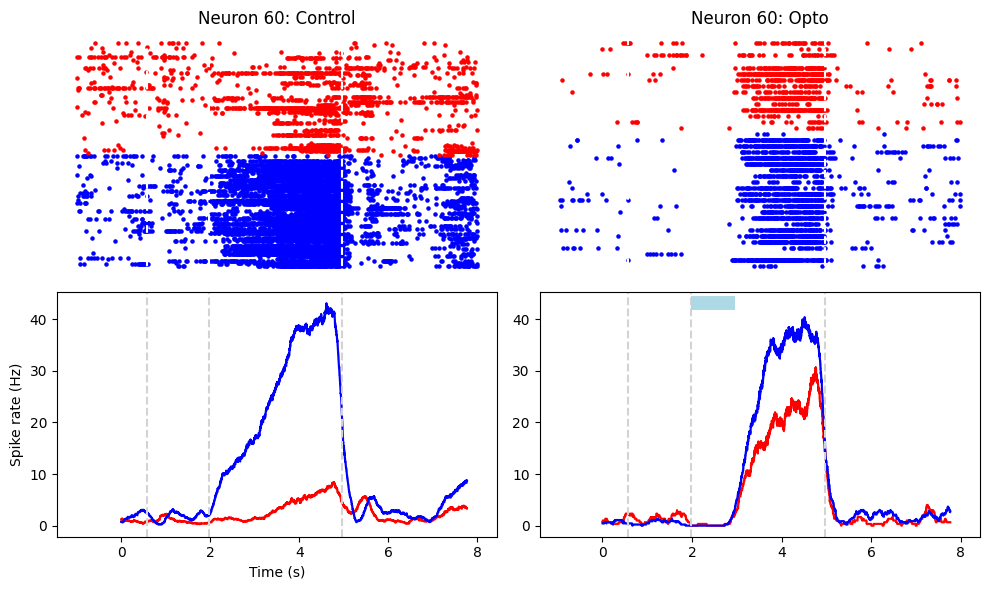

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


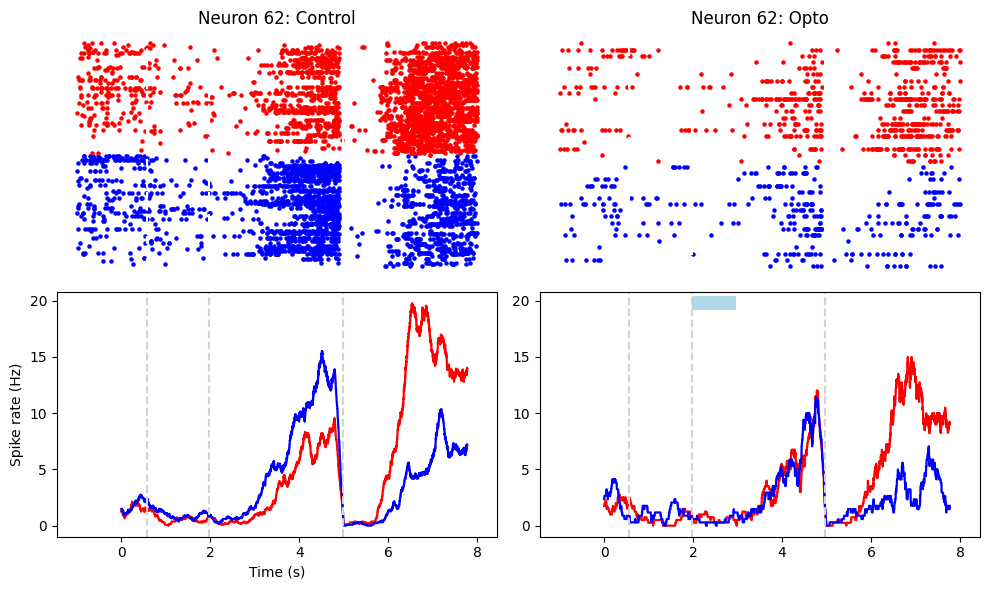

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


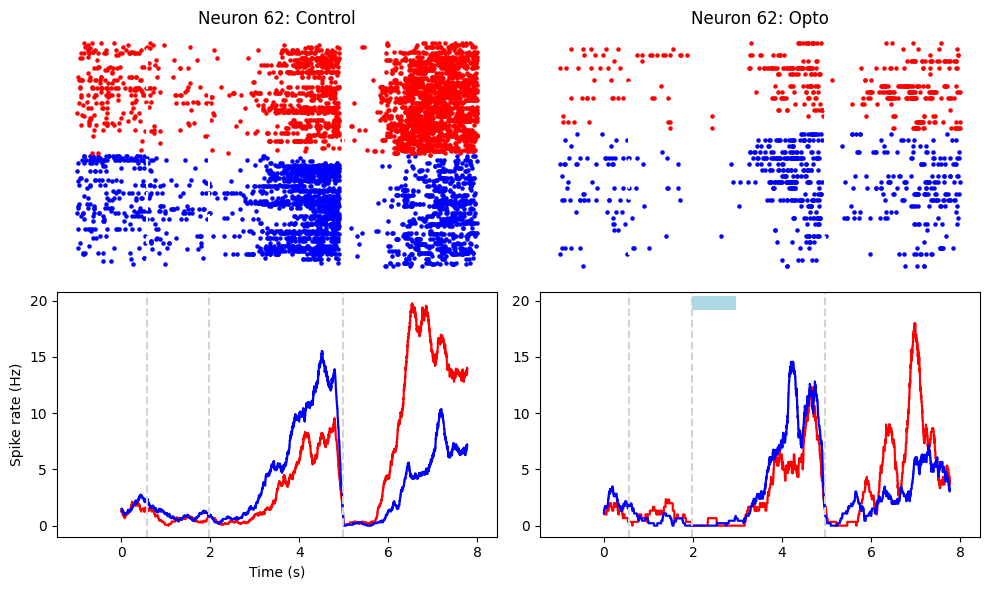

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


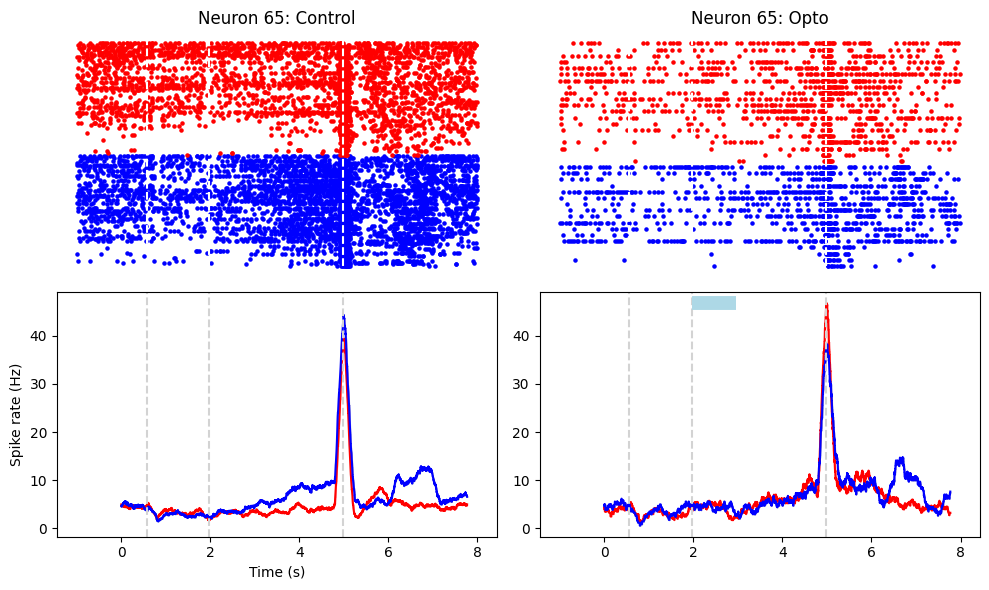

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


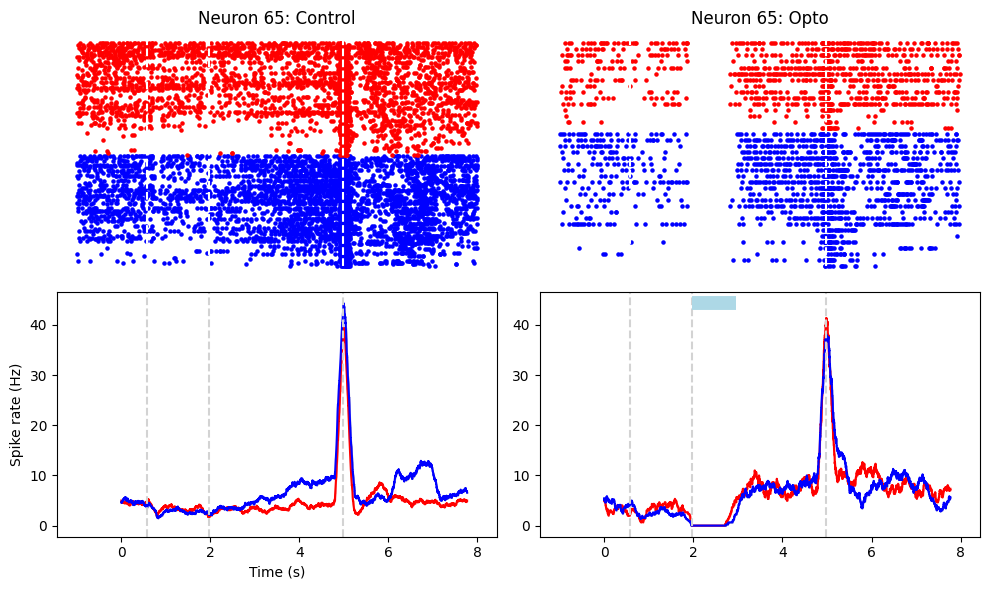

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


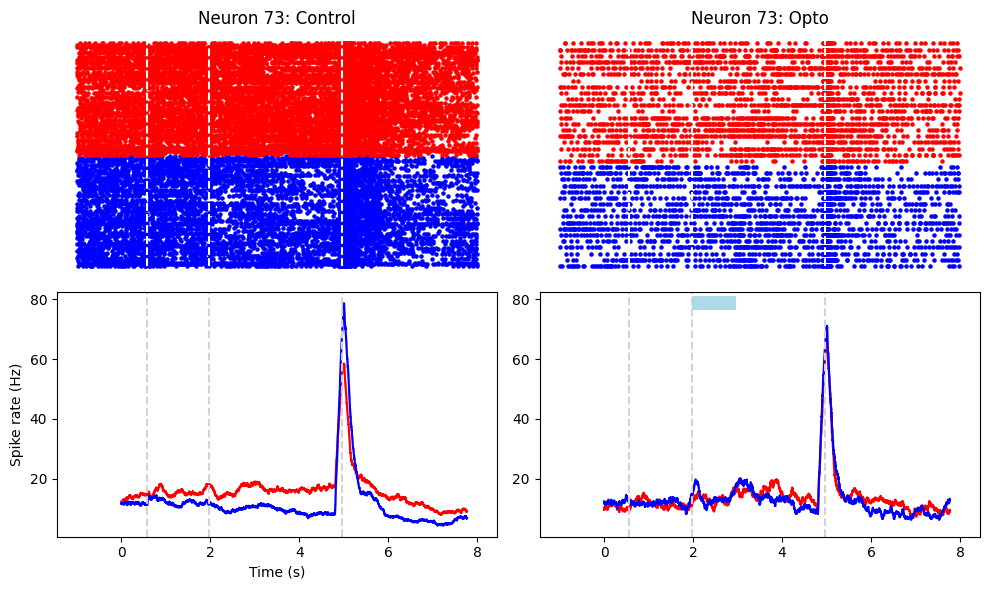

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


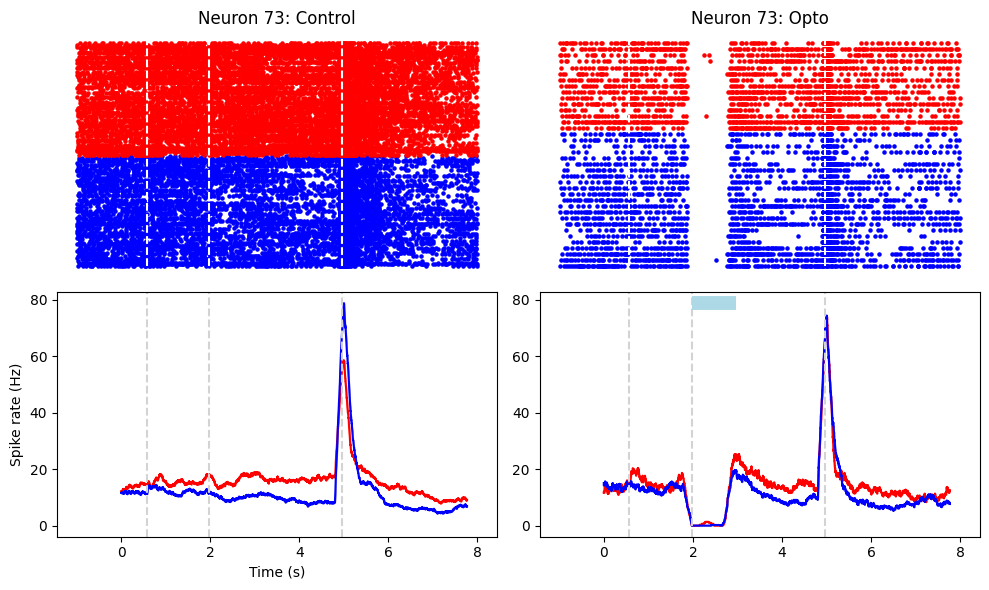

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


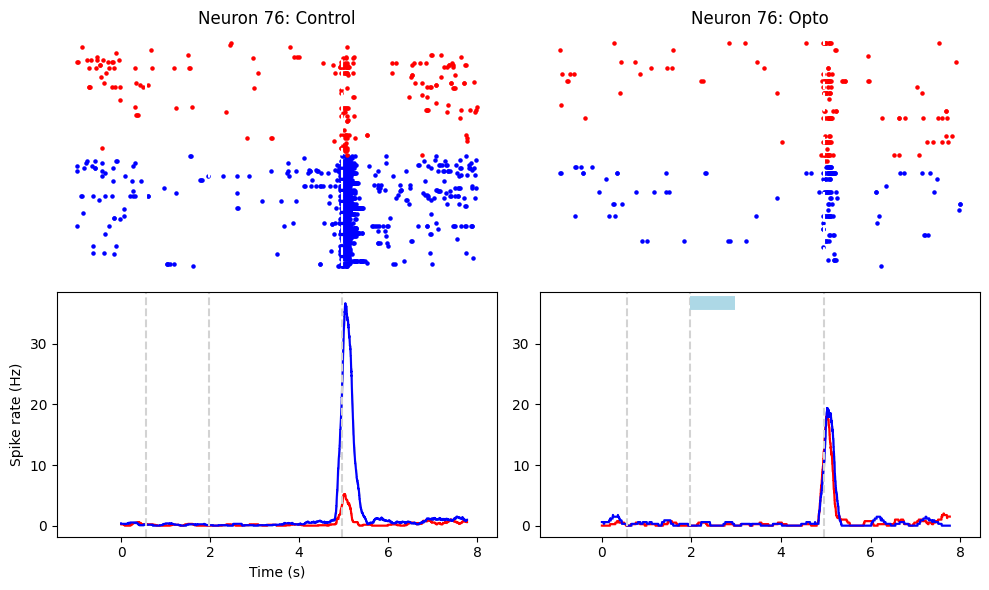

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


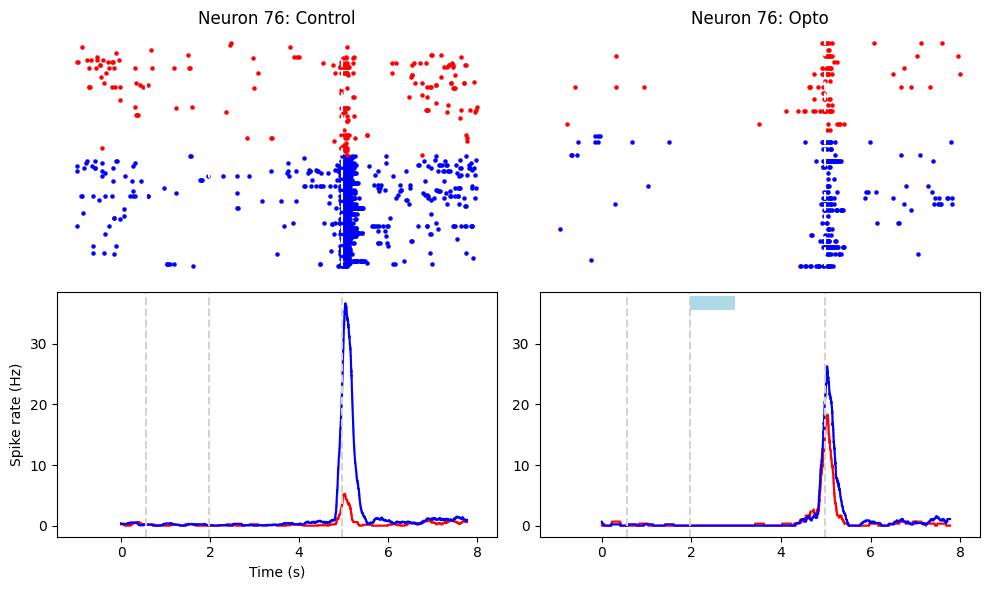

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


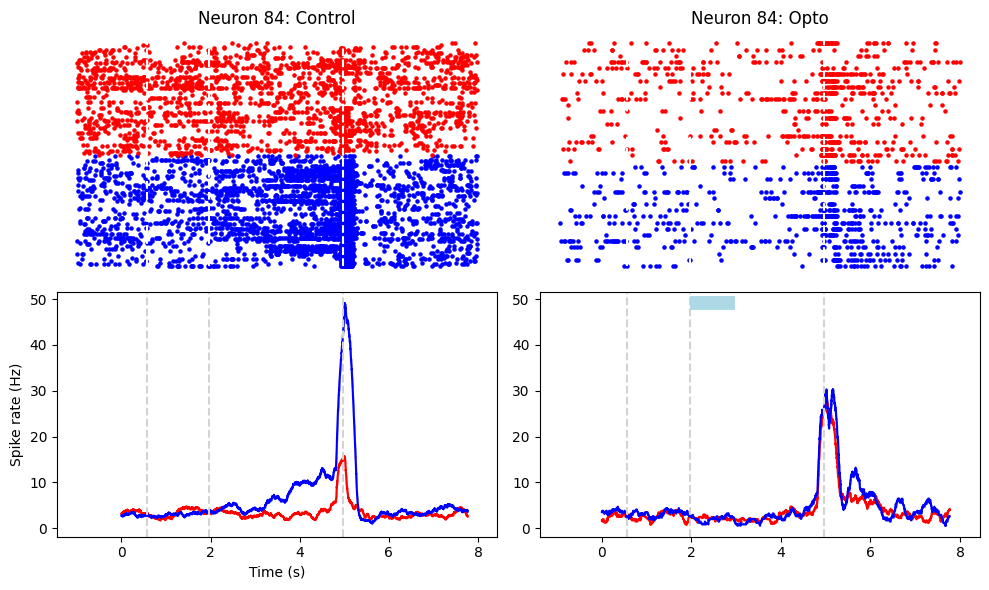

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


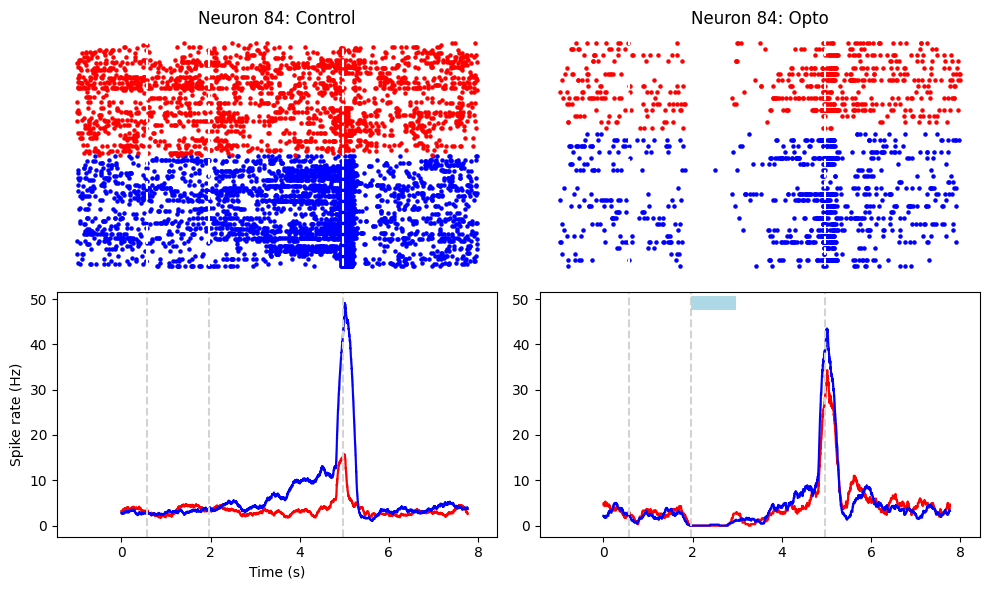

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


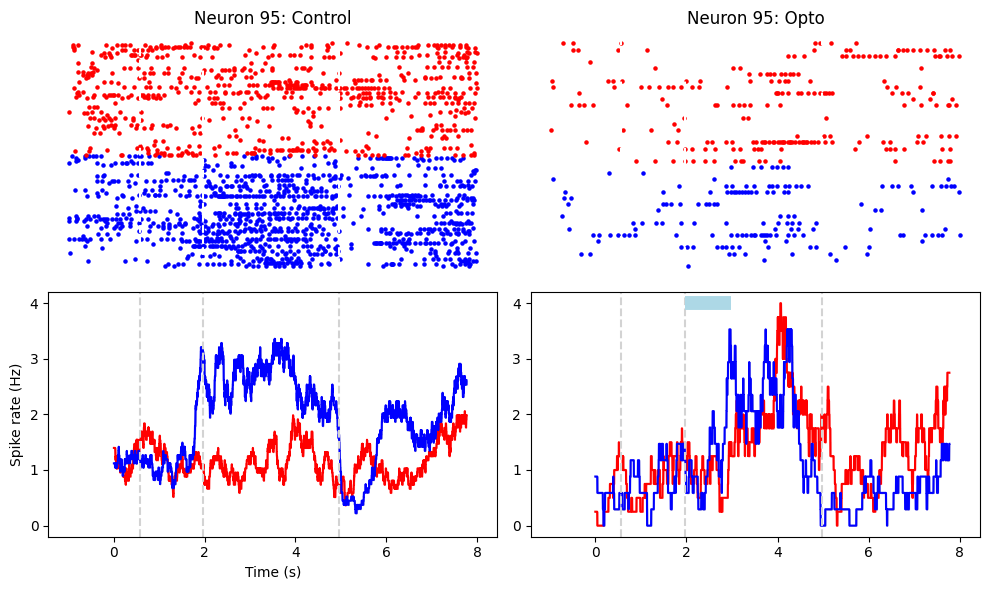

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


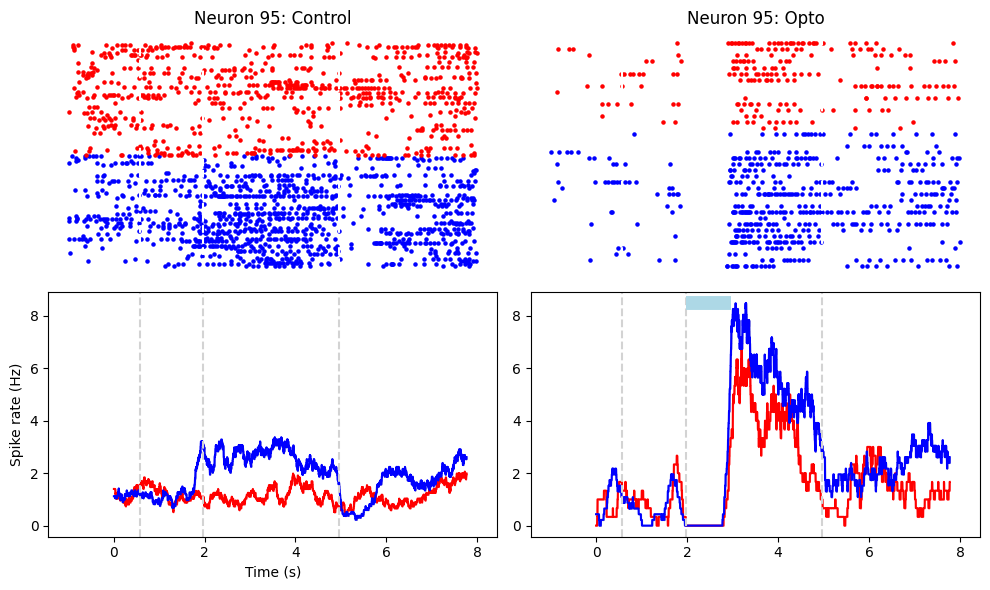

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


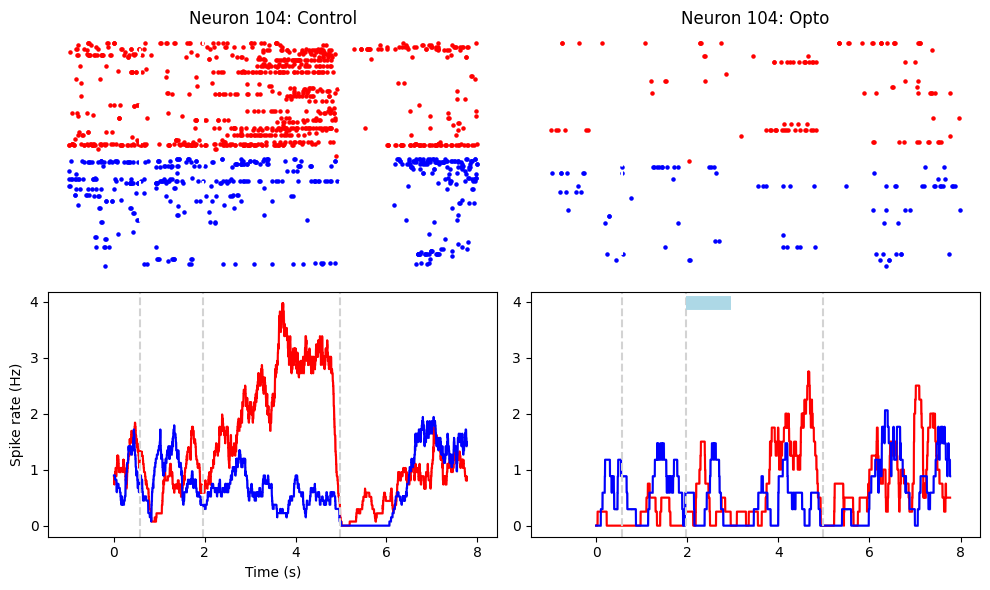

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


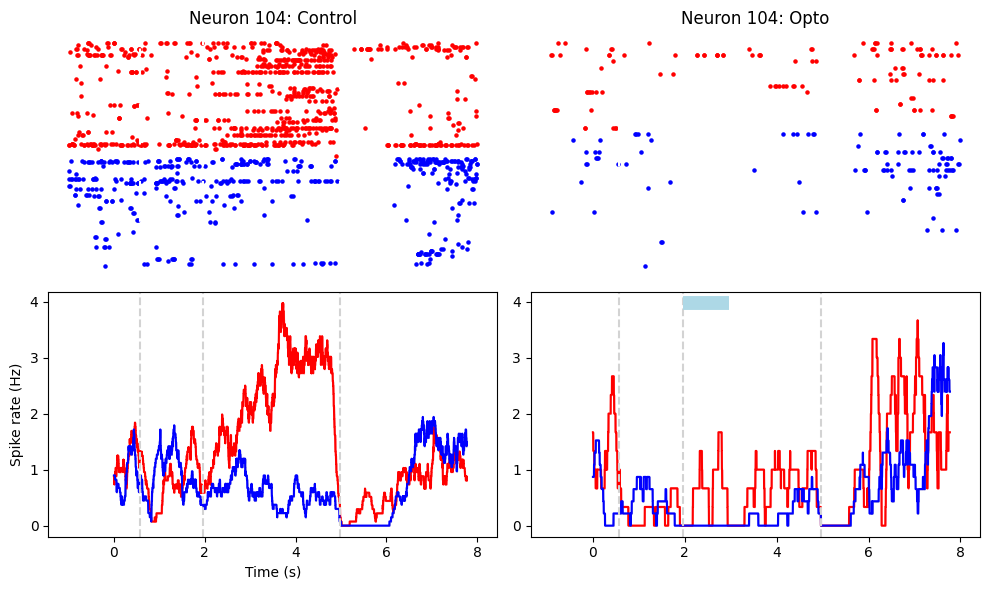

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


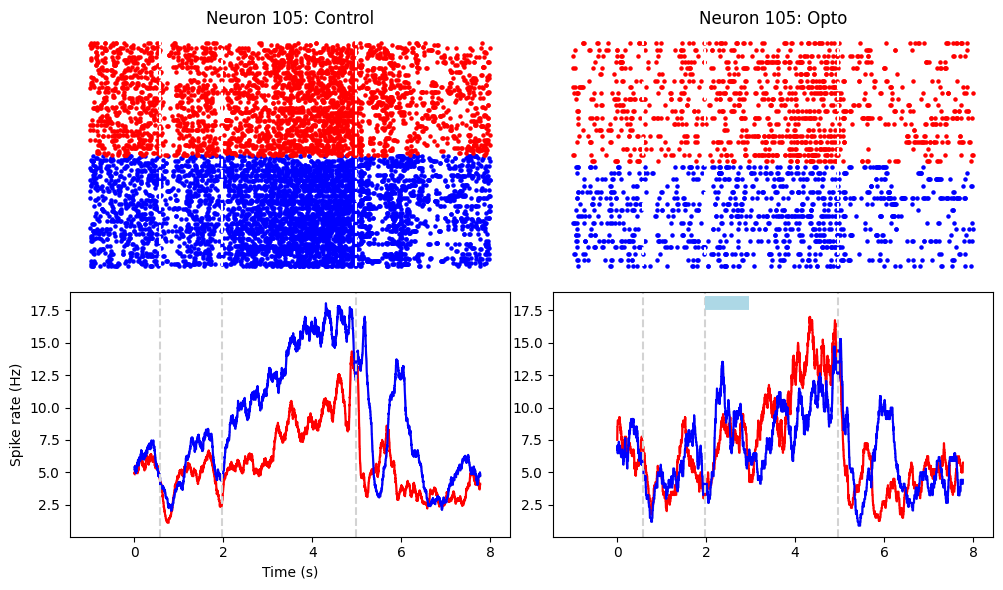

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


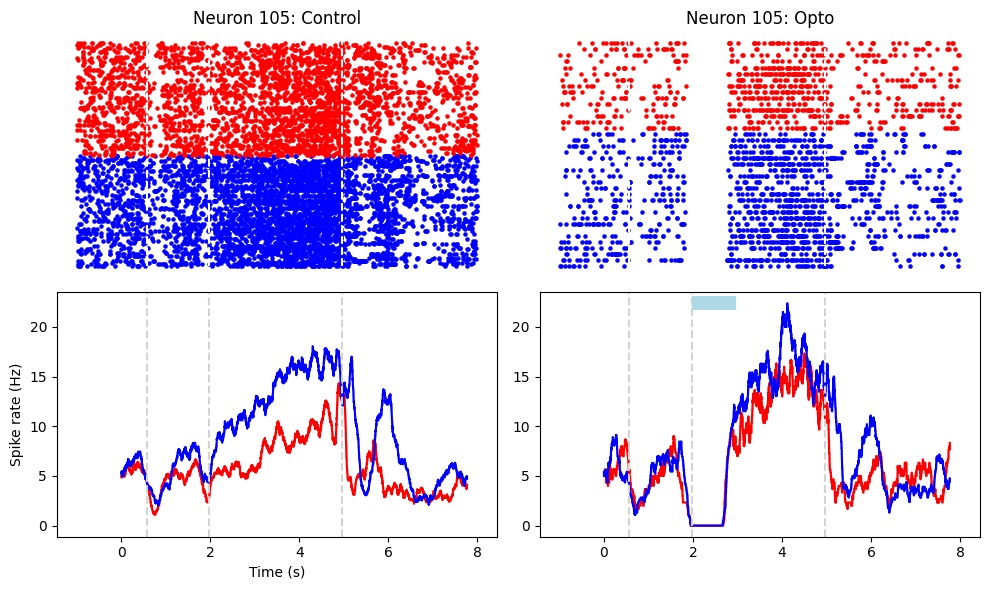

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


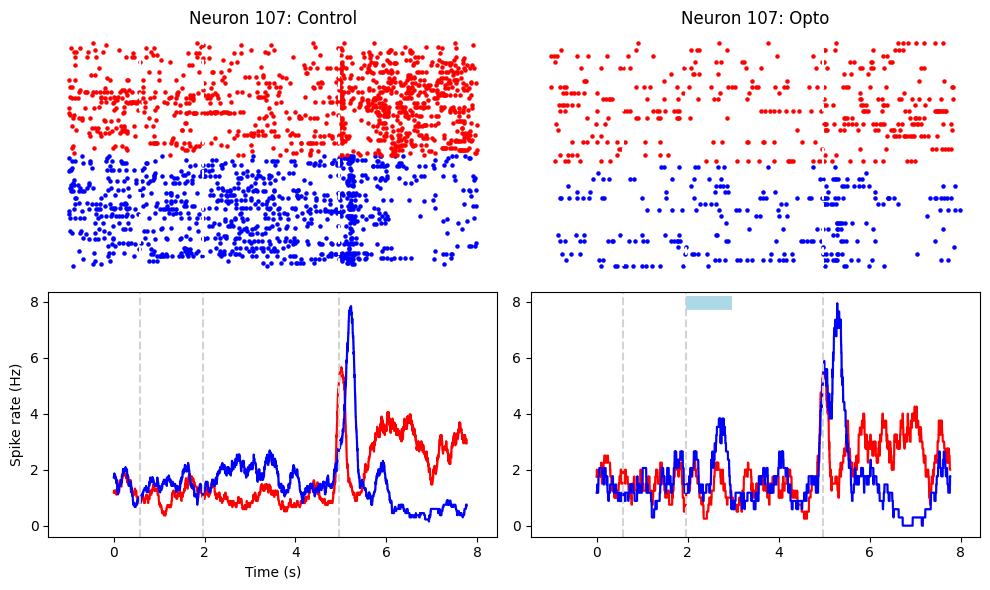

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


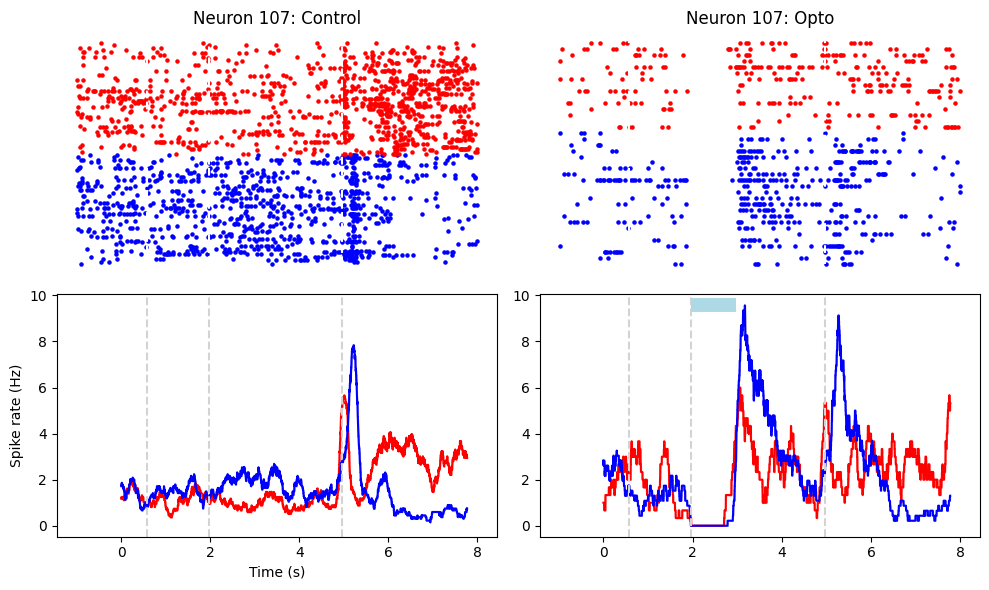

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


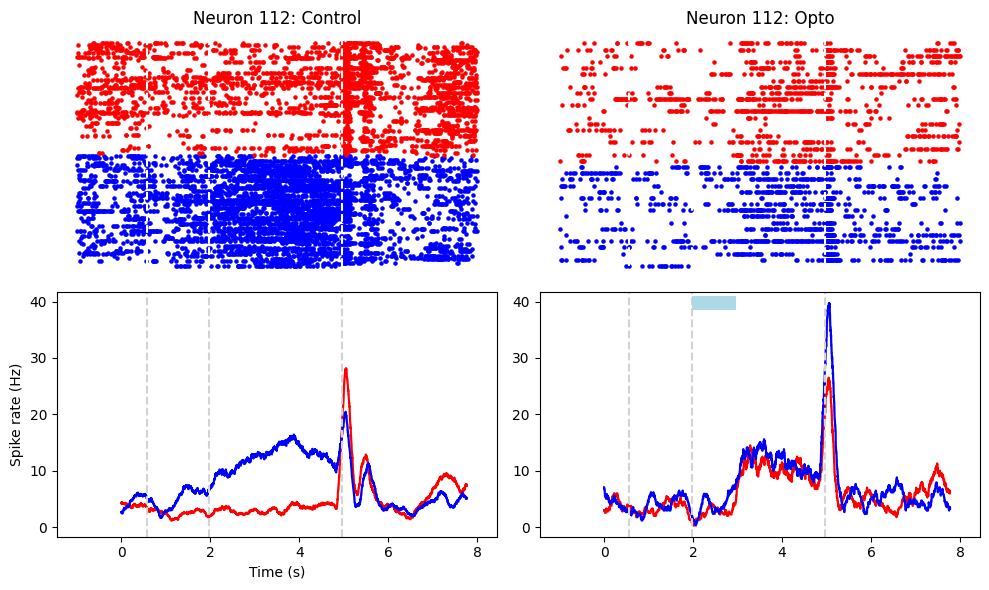

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


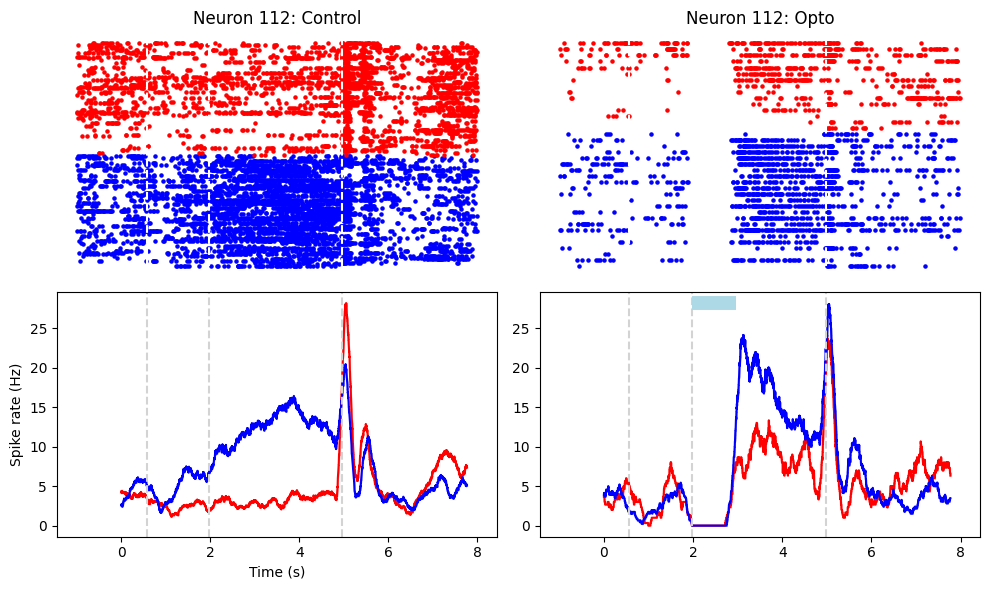

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


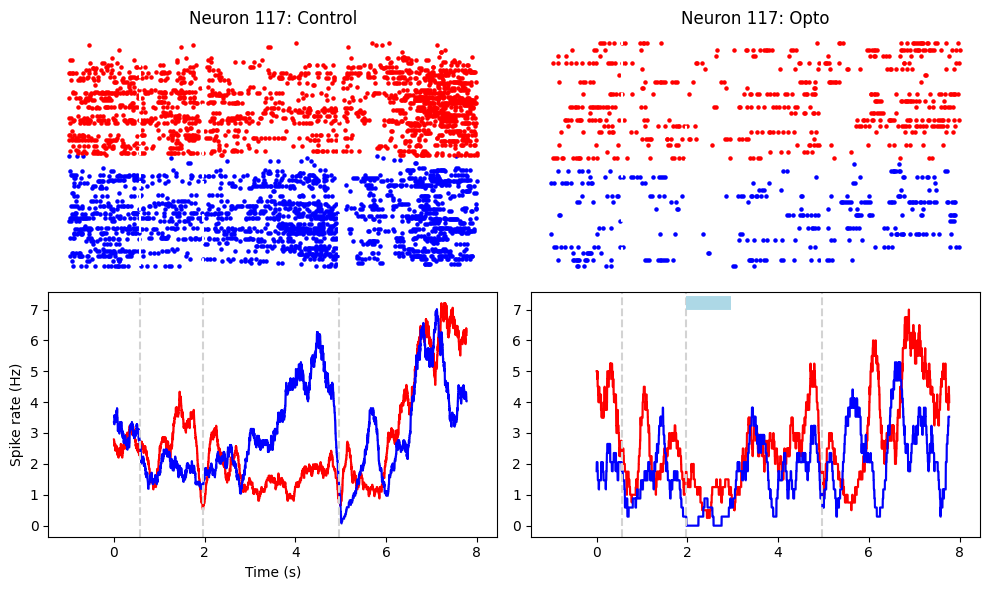

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


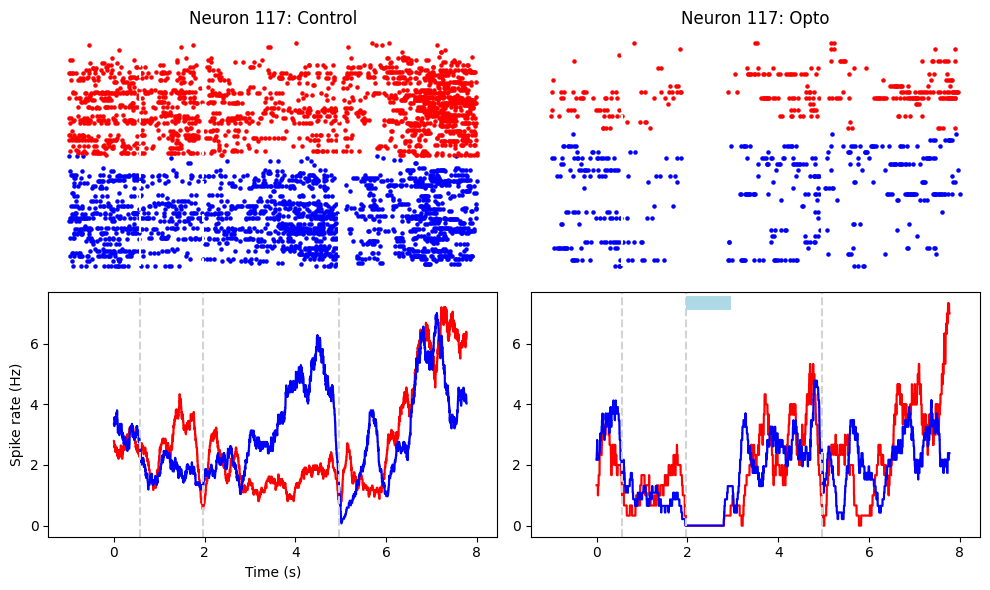

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


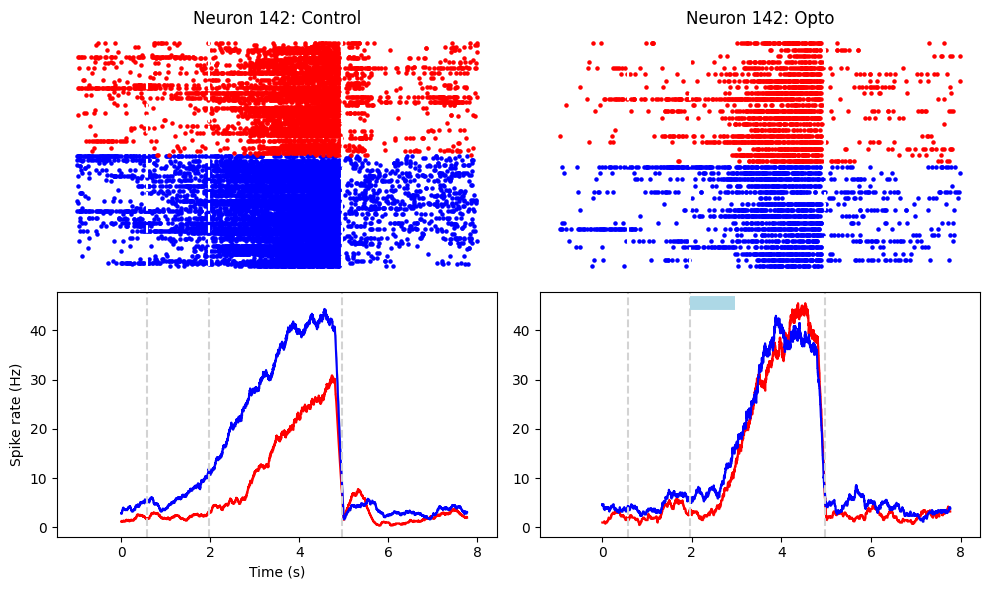

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


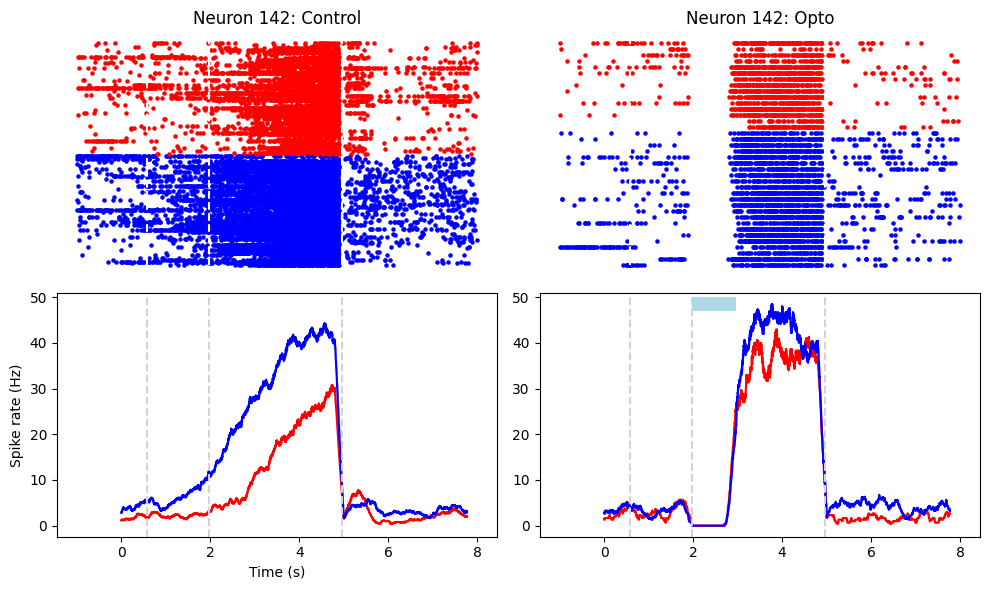

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


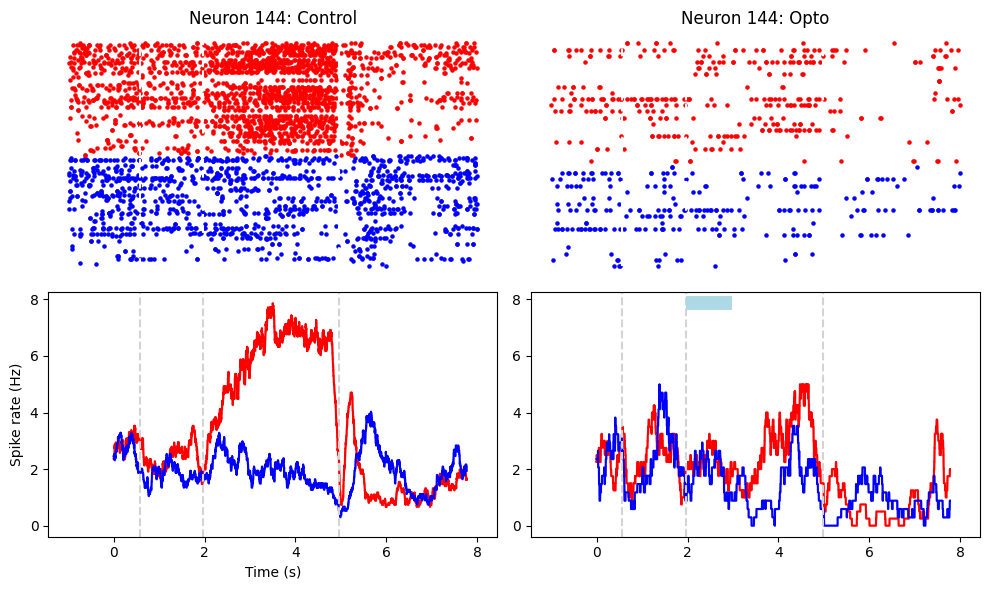

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


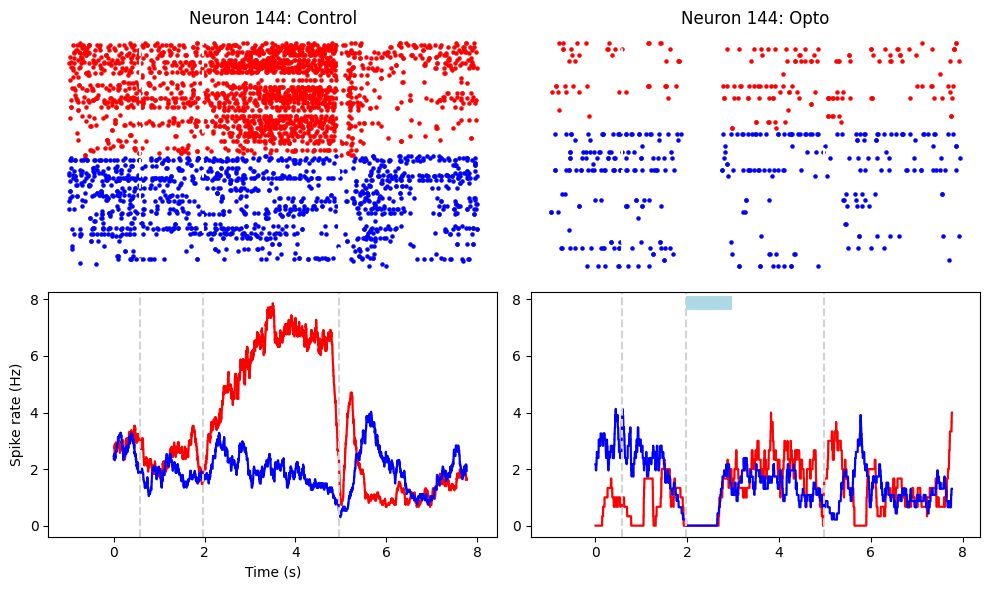

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


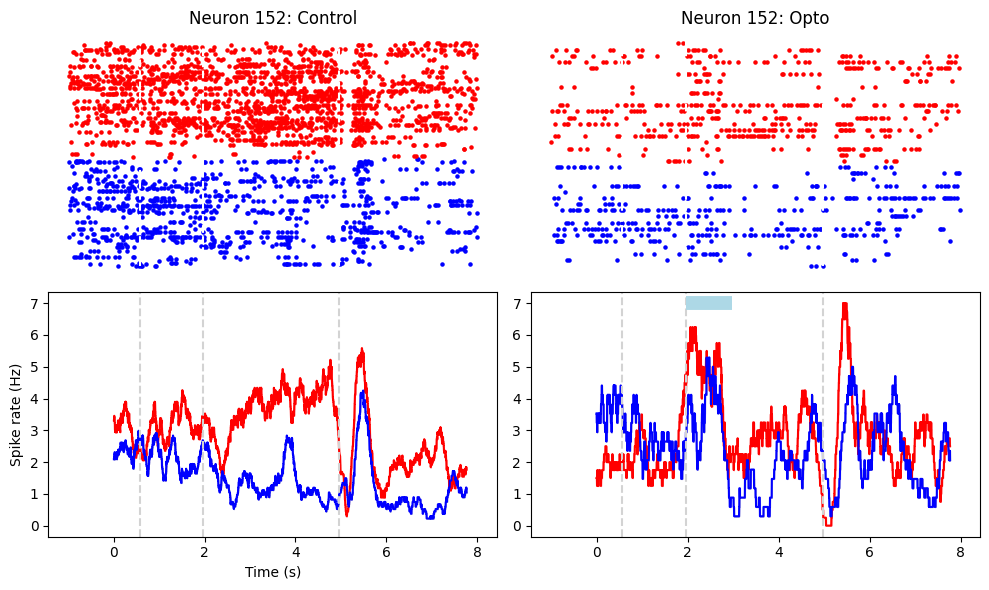

20
24
30
37
59
62
65
72
75
76
77
81
82
85
91
99
105
115
121
122
129
136
140
141
146
150
153
157
169
173
178
179
182
201
207
214
217
223
230
234
236
240
241
249
252
253
256
261
268
269
274
279
284
285
290
291
294
298
304
305
309
315
318
319
330
333
338


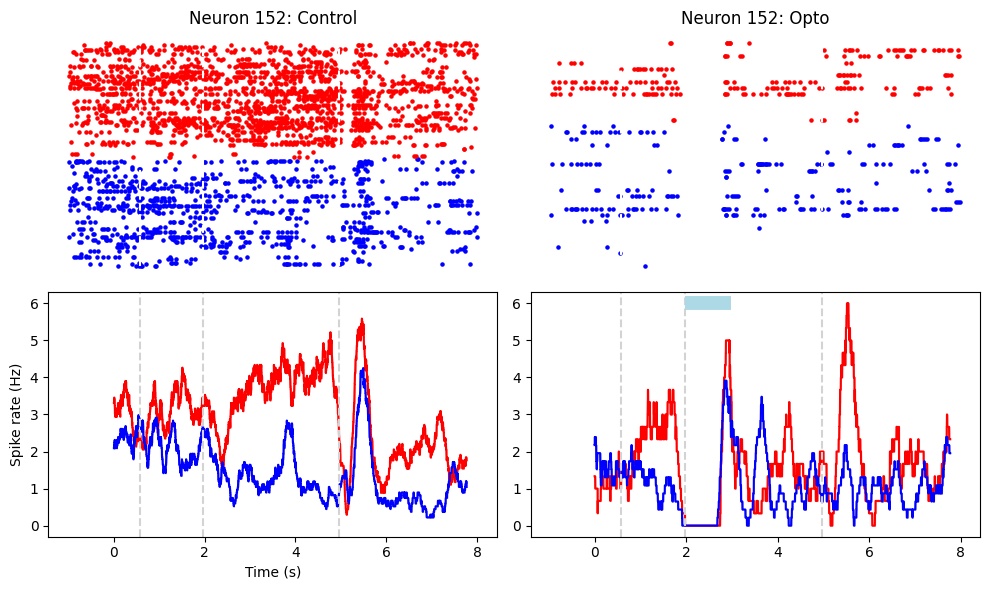

In [37]:
selective_neurons = s1.get_epoch_selective(epoch, p=0.001)
for n in [n for n in selective_neurons if n in s1.L_alm_idx]:
    s1.plot_raster_and_PSTH(n, opto=True, stimside='R')
    s1.plot_raster_and_PSTH(n, opto=True, stimside='L')

## Scatter of modularity  / robustness

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 361 --> 306
Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 321 --> 265
Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 417
HERERER
Remove 21 trials from session for bad behavior
4 trials removed for stability reasons
only ppyr neurons: 368 --> 305
Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 181
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 203 --> 168
Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 280
Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 167


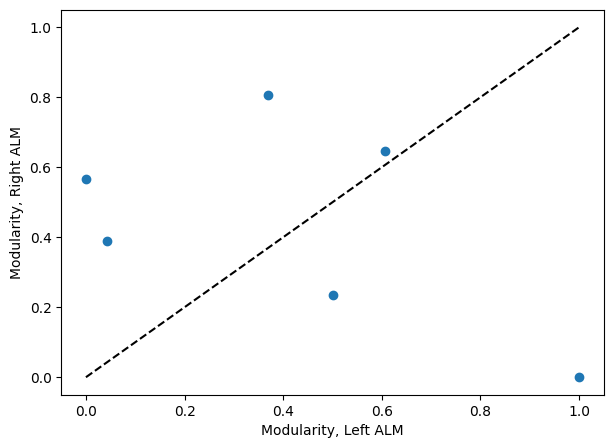

In [55]:
f=plt.figure(figsize=(7,5))
pss =[]
# for path in cat(all_learning_paths_stimcorrected):
paths = trained_paths[-1]
    all_opto_prop_stim_left, all_opto_prop_stim_right = [],[]

    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=True)
        # s1.filter_low_performance(threshold=0.550, consec_len=20)
        epoch = (s1.delay, s1.response)
        # epoch = (s1.sample, s1.delay)
        left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                            p=0.05, 
                                                            # p=0.05/len(s1.good_neurons), 
                                                            binsize=400, 
                                                            timestep=100,
                                                            return_traces=True,
                                                            bootstrap=True)
        # sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
        # sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info
        
        control_sel, opto_sel_stim_left, opto_sel_stim_right, time = left_info
        control_sel_R, opto_sel_stim_left_R, opto_sel_stim_right_R, _ = right_info

        period = np.where((time > s1.delay) & (time < s1.delay + 0.9))[0] # Coupling
        
        # period = np.where((time > s1.delay + 1) & (time < s1.delay + 3))[0] # Robustness
        
        early_delay = np.where((time > s1.delay) & (time < s1.delay + 2))[0]
        late_delay = np.where((time > s1.delay + 2) & (time < s1.response))[0]
        
        # Filtering criteria
        if len(control_sel_R) > 5 and len(control_sel) > 5:
            if np.mean(np.mean(control_sel_R, axis=0)[early_delay]) >= 0.5 and np.mean(np.mean(control_sel, axis=0)[early_delay]) >= 0.5:
                if np.mean(np.mean(control_sel_R, axis=0)[late_delay]) >= 1 and np.mean(np.mean(control_sel, axis=0)[late_delay]) >= 1:
        
                    selo_stimright = np.mean(opto_sel_stim_right, axis=0)
                    sel = np.mean(control_sel, axis=0)
                    selo_stimleft_R = np.mean(opto_sel_stim_left_R, axis=0)
                    sel_R = np.mean(control_sel_R, axis=0)
                    
                    all_opto_prop_stim_left += [np.mean(selo_stimright[period]) / np.mean(sel[period])]
                    all_opto_prop_stim_right += [np.mean(selo_stimleft_R[period]) / np.mean(sel_R[period])]
                    pss += [s1.path]
    # Filtering steps 

    all_opto_prop_stim_left, all_opto_prop_stim_right = np.array(all_opto_prop_stim_left), np.array(all_opto_prop_stim_right)
    all_opto_prop_stim_left[all_opto_prop_stim_left > 1] = 1
    all_opto_prop_stim_right[all_opto_prop_stim_right > 1] = 1
    all_opto_prop_stim_left[all_opto_prop_stim_left < 0] = 0
    all_opto_prop_stim_right[all_opto_prop_stim_right < 0] = 0
    # Plot as a scatter like in Chen et al 
    # modularity of left vs right alm


        

    plt.scatter(all_opto_prop_stim_left, all_opto_prop_stim_right, label = path)
plt.plot([0,1], [0,1], ls='--', color='black')
plt.ylabel('Modularity, Right ALM')
plt.xlabel('Modularity, Left ALM')
# plt.legend()
plt.show()

In [56]:
pss

['K:\\data\\CW84\\python\\2026_03_14',
 'K:\\data\\CW84\\python\\2026_03_15',
 'K:\\data\\CW84\\python\\2026_03_17',
 'K:\\data\\CW84\\python\\2026_03_18',
 'K:\\data\\CW84\\python\\2026_03_19',
 'K:\\data\\CW84\\python\\2026_03_20']

In [58]:
all_opto_prop_stim_right

array([0.38948061, 0.6462349 , 0.23533245, 0.        , 0.80666616,
       0.56547478])

Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 280


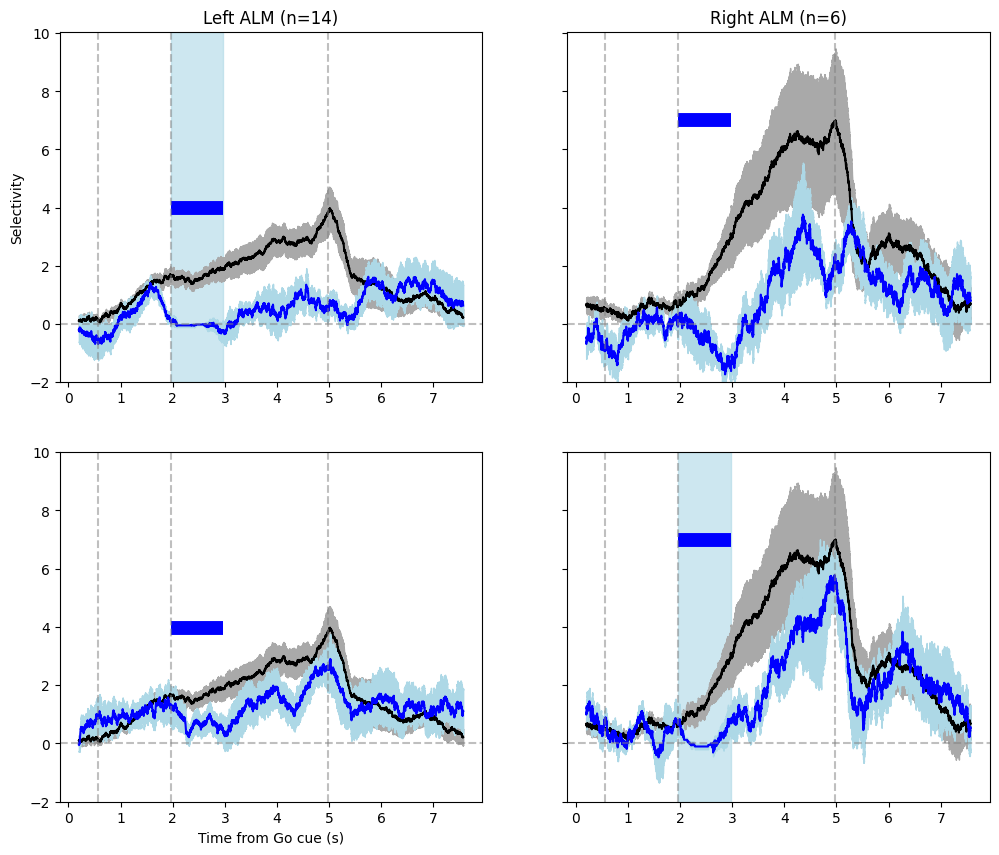

In [100]:
# L dominant FOV
path = r'K:\data\CW84\python\2026_03_19' # L DOM
# path = r'M:\\data\\CW87\\python\\2026_02_20'
s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01/len(s1.good_neurons), 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info) #, save=r'P:\')

In [102]:
left_info, right_info

(None, None)

### Robustness

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 175
[] []
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 344
[] []
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 238
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 287
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 287
[1. 1.] [0.51997879 0.        ]
Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 205
Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 145
Loading good trial inds from file
29 trials removed for stability reasons
only ppyr neurons: 484 --> 389
[0.48292029 0.56759635] [0.31056658 0.46751032]
Loading good trial inds from file
15 trials removed for stability reasons


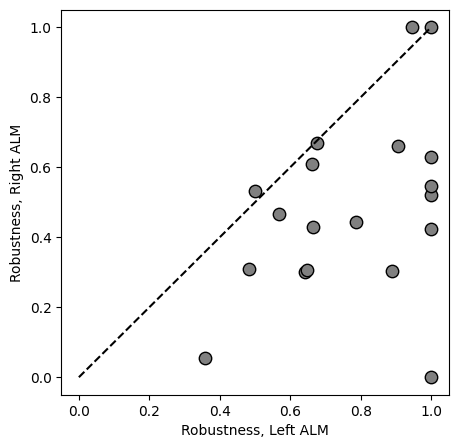

In [113]:
f=plt.figure(figsize=(5,5))
save_all = []
savepaths = []
# for path in cat(all_learning_paths_stimcorrected):
for paths in trained_paths:
    all_opto_prop_stim_left, all_opto_prop_stim_right = [],[]

    for path in paths:
        s1 = Session(path, passive=False, filter_low_perf=True, filter_by_stim=True)
        # s1.filter_low_performance(threshold=0.550, consec_len=20)
        epoch = (s1.delay+1, s1.response)
        # epoch = (s1.sample, s1.delay)
        left_info, right_info = s1.selectivity_optogenetics(epoch=epoch,
                                                            p=0.01, 
                                                            # p=0.05/len(s1.good_neurons), 
                                                            binsize=400, 
                                                            timestep=100,
                                                            return_traces=True,
                                                            bootstrap=True)
        # sel, selo_stimleft, selo_stimright, err, erro_stimleft, erro_stimright, time = left_info
        # sel_R, selo_stimleft_R, selo_stimright_R, err_R, erro_stimleft_R, erro_stimright_R, time = right_info

        if left_info is None or right_info is None:
            continue
        
        control_sel, opto_sel_stim_left, opto_sel_stim_right, time = left_info
        control_sel_R, opto_sel_stim_left_R, opto_sel_stim_right_R, _ = right_info
    
        period = np.where((time > s1.delay+0.1) & (time < s1.delay + 0.9))[0] # Coupling
        
        period = np.where((time > s1.delay + 1) & (time < s1.delay + 3))[0] # Robustness (usually 2-3s)
    
        early_delay = np.where((time > s1.delay) & (time < s1.delay + 1))[0]
        late_delay = np.where((time > s1.delay + 2) & (time < s1.response))[0]
        
        # Filtering criteria
        if len(control_sel_R) > 5 and len(control_sel) > 5: # or 5
            if np.mean(np.mean(control_sel_R, axis=0)[early_delay]) >= 0.3 and np.mean(np.mean(control_sel, axis=0)[early_delay]) >= 0.3:
                if np.mean(np.mean(control_sel_R, axis=0)[late_delay]) >= 1 and np.mean(np.mean(control_sel, axis=0)[late_delay]) >= 1:
        
                    selo_stimright = np.mean(opto_sel_stim_right, axis=0)
                    selo_stimright_R = np.mean(opto_sel_stim_right_R, axis=0)
                    sel = np.mean(control_sel, axis=0)
                    selo_stimleft_R = np.mean(opto_sel_stim_left_R, axis=0)
                    selo_stimleft = np.mean(opto_sel_stim_left, axis=0)
                    sel_R = np.mean(control_sel_R, axis=0)
                    
                    # Use both hemispheres for robustness calculations

                    # all_opto_prop_stim_right += [np.mean([np.mean(selo_stimleft_R[period]) / np.mean(sel_R[period]),
                    #                                     np.mean(selo_stimleft[period]) / np.mean(sel[period])])]

                    # all_opto_prop_stim_left += [np.mean([np.mean(selo_stimright_R[period]) / np.mean(sel_R[period]), 
                    #                                       np.mean(selo_stimright[period]) / np.mean(sel[period])])]

                    # use single hemi for robustness

                    all_opto_prop_stim_left += [np.mean(selo_stimright[period]) / np.mean(sel[period])]
                    all_opto_prop_stim_right += [np.mean(selo_stimleft_R[period]) / np.mean(sel_R[period])]


                    save_all += [[all_opto_prop_stim_left, all_opto_prop_stim_right]]
                    savepaths += [path]

    # Filtering steps 
    
    all_opto_prop_stim_left, all_opto_prop_stim_right = np.array(all_opto_prop_stim_left), np.array(all_opto_prop_stim_right)
    all_opto_prop_stim_left[all_opto_prop_stim_left > 1] = 1
    all_opto_prop_stim_right[all_opto_prop_stim_right > 1] = 1
    all_opto_prop_stim_left[all_opto_prop_stim_left < 0] = 0
    all_opto_prop_stim_right[all_opto_prop_stim_right < 0] = 0
    # Plot as a scatter like in Chen et al 
    # modularity of left vs right alm
    
    print(all_opto_prop_stim_left, all_opto_prop_stim_right)
    
    plt.scatter(all_opto_prop_stim_left, all_opto_prop_stim_right, s=80, c='grey', edgecolors='black')
plt.plot([0,1], [0,1], ls='--', color='black')
plt.ylabel('Robustness, Right ALM')
plt.xlabel('Robustness, Left ALM')
# plt.savefig(r'P:\paperfigures\fig1\robustness_scatter.pdf')
# plt.legend()
plt.show()

[[0.6285716869422352, 0.7669163449921915, 0.09853944447066408],
 [1.4599684070971828, 1.1572679401217385, -0.17132930050153541]]

['L:\\data\\CW68\\python\\2025_12_10',
 'L:\\data\\CW68\\python\\2025_12_12',
 'L:\\data\\CW68\\python\\2025_12_13',
 'H:\\ephys_data\\CW47\\python\\2024_10_22',
 'H:\\ephys_data\\CW47\\python\\2024_10_25',
 'K:\\data\\CW85\\python\\2026_02_07',
 'M:\\data\\CW87\\python\\2026_02_20',
 'M:\\data\\CW87\\python\\2026_02_21',
 'K:\\data\\CW84\\python\\2026_03_14',
 'K:\\data\\CW84\\python\\2026_03_15',
 'K:\\data\\CW84\\python\\2026_03_16',
 'K:\\data\\CW84\\python\\2026_03_17',
 'K:\\data\\CW84\\python\\2026_03_18',
 'K:\\data\\CW84\\python\\2026_03_19',
 'K:\\data\\CW84\\python\\2026_03_20']

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 361


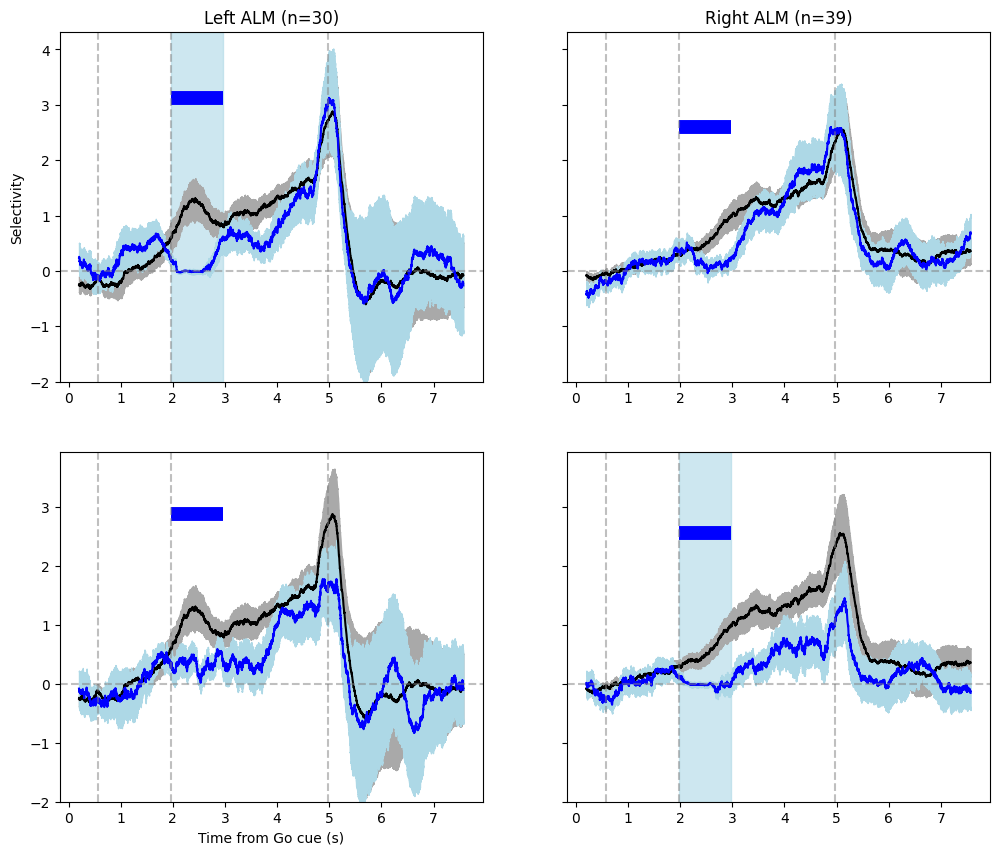

In [16]:
# check outliers

path = r'L:\\data\\CW68\\python\\2025_12_12'
s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True, remove_consec_opto=False)
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.01, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)

Loading good trial inds from file
14 trials removed for stability reasons
Removed 47 consecutive stim trials
only ppyr neurons: 321 --> 262


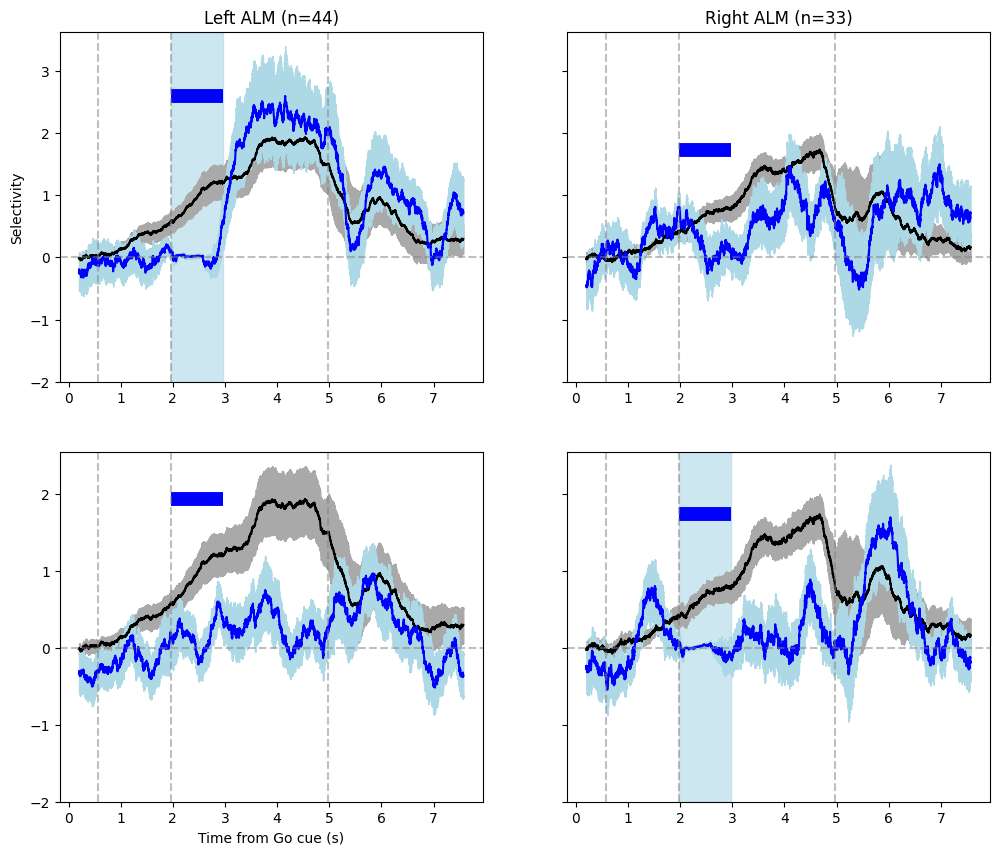

In [5]:
# check outliers

path =  r'K:\data\CW84\python\2026_03_14'
s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True, remove_consec_opto=True)
epoch = (s1.delay, s1.response)
left_info, right_info = s1.selectivity_optogenetics(epoch = epoch,
                                                    p=0.05, 
                                                    binsize=400, 
                                                    timestep=150,
                                                    # binsize=200, 
                                                    # timestep=100,
                                                    bootstrap=True)

plot_selectivity_recovery(s1, left_info, right_info)

In [107]:
# Save single neuron PSTHs

# path =  r'K:\data\CW84\python\2026_03_14'
# s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True, remove_consec_opto=False)
# epoch = (s1.delay, s1.response)

# selective_neurons = s1.get_epoch_selective(epoch, p=0.05)
# for n in [n for n in selective_neurons if n in s1.L_alm_idx]:
#     s1.plot_raster_and_PSTH(n, opto=True, stimside='both', save = path + '\\left_neuron_{}.png'.format(n))
# for n in [n for n in selective_neurons if n in s1.R_alm_idx]:
#     s1.plot_raster_and_PSTH(n, opto=True, stimside='both', save = path + '\\right_neuron_{}.png'.format(n))


# path = r'L:\\data\\CW68\\python\\2025_12_13'
# s1=Session(path, passive=False, filter_low_perf=True, filter_by_stim=True, remove_consec_opto=False)
# epoch = (s1.delay, s1.response)

# selective_neurons = s1.get_epoch_selective(epoch, p=0.05)
# for n in [n for n in selective_neurons if n in s1.L_alm_idx]:
#     s1.plot_raster_and_PSTH(n, opto=True, stimside='both', save = path + '\\left_neuron_{}.png'.format(n))
# for n in [n for n in selective_neurons if n in s1.R_alm_idx]:
#     s1.plot_raster_and_PSTH(n, opto=True, stimside='both', save = path + '\\right_neuron_{}.png'.format(n))